# Fire & Smoke Detection - Google Colab
## Production Ready Notebook

**Status:** All Bugs Fixed | Ready to Train
**Runtime:** 3-5 hours

### Instructions:
1. Replace YOUR_API_KEY in Cell 8
2. Enable GPU: Runtime → Change runtime type → GPU
3. Run all cells: Ctrl+F9
4. Download model after training

**That's it! Everything else is automatic.**


In [ ]:
import subprocess
import sys

print("Installing packages...")
subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
    "ultralytics", "roboflow", "opencv-python", "pyyaml",
    "torch", "numpy", "matplotlib", "pillow", "tqdm"])
print("All packages installed successfully!")


Installing packages...
All packages installed successfully!


In [ ]:
import torch
import yaml
import json
import logging
import time
import warnings
from pathlib import Path
from typing import List, Optional, Dict, Generator
from dataclasses import dataclass, field
from datetime import datetime
import numpy as np

warnings.filterwarnings('ignore')

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    mem = torch.cuda.get_device_properties(0).total_memory / 1e9
    print("GPU Memory:", f"{mem:.2f} GB")
else:
    print("WARNING: GPU not available. Training will be slower.")


PyTorch version: 2.10.0+cu128
CUDA available: True
GPU: Tesla T4
GPU Memory: 15.64 GB


In [ ]:
from pathlib import Path

class ConfigError(Exception):
    pass

@dataclass
class DatasetConfig:
    roboflow_api_key: str
    workspace_name: str = "affan-zulfiqar-fireguard"
    project_name: str = "fire_smoke_paf_iast"
    version: int = 1
    format: str = "yolo26"

@dataclass
class TrainingConfig:
    model_name: str = "yolo26n.pt"
    epochs: int = 2
    batch_size: int = 16
    imgsz: int = 640
    device: str = "cuda"
    patience: int = 10
    save_period: int = 5
    optimizer: str = "SGD"
    lr0: float = 0.01
    lrf: float = 0.01
    momentum: float = 0.937
    weight_decay: float = 0.0005
    warmup_epochs: int = 3
    workers: int = 4
    seed: int = 42

@dataclass
class ValidationConfig:
    save_json: bool = True
    save_txt: bool = True
    iou_thres: float = 0.6
    conf_thres: float = 0.55

@dataclass
class PredictionConfig:
    conf_threshold: float = 0.55
    iou_threshold: float = 0.47
    max_det: int = 300

@dataclass
class ModelConfig:
    dataset: DatasetConfig
    training: TrainingConfig
    validation: ValidationConfig
    prediction: PredictionConfig

    base_dir: Path = Path("./fire_detection_model")
    output_dir: Path = field(default=None)
    logs_dir: Path = field(default=None)
    checkpoints_dir: Path = field(default=None)
    models_dir: Path = field(default=None)
    datasets_dir: Path = field(default=None)

    project_name: str = "Fire Detection System"
    model_version: str = "1.0.0"

    def __post_init__(self):
        try:
            self.base_dir = Path(self.base_dir).resolve()
            self.base_dir.mkdir(parents=True, exist_ok=True)

            self.output_dir = self.base_dir / "outputs"
            self.logs_dir = self.base_dir / "logs"
            self.checkpoints_dir = self.base_dir / "checkpoints"
            self.models_dir = self.base_dir / "models"
            self.datasets_dir = self.base_dir / "datasets"

            for directory in [self.output_dir, self.logs_dir, self.checkpoints_dir,
                            self.models_dir, self.datasets_dir]:
                directory.mkdir(parents=True, exist_ok=True)

            print("[CONFIG] Directories created:")
            print(f"  Base: {self.base_dir}")
            print(f"  Logs: {self.logs_dir}")
            print(f"  Outputs: {self.output_dir}")

        except Exception as e:
            raise ConfigError(f"Directory creation failed: {e}")

def get_default_config(api_key: str):
    if not api_key or len(api_key) < 10:
        raise ConfigError("Invalid API key")

    config = ModelConfig(
        dataset=DatasetConfig(roboflow_api_key=api_key),
        training=TrainingConfig(),
        validation=ValidationConfig(),
        prediction=PredictionConfig(),
    )
    return config

print("Configuration module loaded!")


Configuration module loaded!


In [ ]:
import logging
import logging.handlers

class SimpleLogger:
    def __init__(self, name: str, log_dir: Path):
        self.name = name
        self.log_dir = Path(log_dir)
        self.log_dir.mkdir(parents=True, exist_ok=True)

        self.logger = logging.getLogger(name)
        self.logger.setLevel(logging.INFO)
        self.logger.handlers = []

        console_handler = logging.StreamHandler()
        console_handler.setFormatter(logging.Formatter(
            '%(asctime)s - %(levelname)s - %(message)s',
            datefmt='%Y-%m-%d %H:%M:%S'
        ))
        self.logger.addHandler(console_handler)

        log_file = self.log_dir / f"{name}.log"
        file_handler = logging.handlers.RotatingFileHandler(
            str(log_file), maxBytes=10*1024*1024, backupCount=5
        )
        file_handler.setFormatter(logging.Formatter(
            '%(asctime)s - %(levelname)s - %(message)s'
        ))
        self.logger.addHandler(file_handler)

    def info(self, msg: str):
        self.logger.info(msg)

    def error(self, msg: str):
        self.logger.error(msg)

    def warning(self, msg: str):
        self.logger.warning(msg)

print("Logger module loaded!")


Logger module loaded!


In [ ]:
class FireDetectionError(Exception):
    pass

class ConfigurationError(FireDetectionError):
    pass

class DatasetError(FireDetectionError):
    pass

class RoboflowError(DatasetError):
    pass

class ModelError(FireDetectionError):
    pass

class TrainingError(FireDetectionError):
    pass

class InferenceError(FireDetectionError):
    pass

print("Exception module loaded!")


Exception module loaded!


In [ ]:
from dataclasses import dataclass
from typing import List

@dataclass
class Detection:
    class_id: int
    class_name: str
    confidence: float
    x_min: float
    y_min: float
    x_max: float
    y_max: float

@dataclass
class InferenceResult:
    image_path: str
    timestamp: float
    detections: List[Detection]
    inference_time_ms: float

    @property
    def has_fire(self):
        return any(d.class_name.lower() == 'fire' for d in self.detections)

    @property
    def has_smoke(self):
        return any(d.class_name.lower() == 'smoke' for d in self.detections)

    @property
    def max_fire_confidence(self):
        fire_dets = [d for d in self.detections if d.class_name.lower() == 'fire']
        return max([d.confidence for d in fire_dets]) if fire_dets else 0.0

class InferenceEngine:
    def __init__(self, model_path: str, config: ModelConfig, logger: SimpleLogger):
        self.model_path = Path(model_path)
        self.config = config
        self.logger = logger
        self.model = None
        self.class_names = {}

        if not self.model_path.exists():
            raise FileNotFoundError(f"Model not found: {model_path}")

        self._load_model()

    def _load_model(self):
        try:
            from ultralytics import YOLO
            self.logger.info(f"Loading model: {self.model_path}")
            self.model = YOLO(str(self.model_path))
            if hasattr(self.model, 'names'):
                self.class_names = self.model.names
            self.logger.info(f"Model loaded with {len(self.class_names)} classes")
        except Exception as e:
            raise ModelError(f"Failed to load model: {e}")

    def predict(self, image_path: str):
        image_path = Path(image_path)
        if not image_path.exists():
            raise FileNotFoundError(f"Image not found: {image_path}")

        try:
            start_time = time.time()
            results = self.model.predict(
                source=str(image_path),
                conf=self.config.prediction.conf_threshold,
                iou=self.config.prediction.iou_threshold,
                max_det=self.config.prediction.max_det,
                verbose=False
            )
            inference_time_ms = (time.time() - start_time) * 1000

            detections = self._parse_detections(results[0])

            return InferenceResult(
                image_path=str(image_path),
                timestamp=time.time(),
                detections=detections,
                inference_time_ms=inference_time_ms
            )
        except Exception as e:
            raise InferenceError(f"Inference failed: {e}")

    def predict_stream(self, image_paths: List[str]):
        total = len(image_paths)
        for idx, image_path in enumerate(image_paths, 1):
            try:
                result = self.predict(image_path)
                yield result
                if idx % 100 == 0:
                    self.logger.info(f"Processed {idx}/{total} images")
            except Exception as e:
                self.logger.warning(f"Failed: {image_path}")
                continue

    def _parse_detections(self, result):
        detections = []
        try:
            if hasattr(result, 'boxes') and result.boxes is not None:
                boxes = result.boxes.data.cpu().numpy()
                for box in boxes:
                    x_min, y_min, x_max, y_max, conf, cls_id = box
                    class_name = self.class_names.get(int(cls_id), f"class_{int(cls_id)}")
                    detection = Detection(
                        class_id=int(cls_id),
                        class_name=class_name,
                        confidence=float(conf),
                        x_min=float(x_min),
                        y_min=float(y_min),
                        x_max=float(x_max),
                        y_max=float(y_max)
                    )
                    detections.append(detection)
        except Exception as e:
            print(f"Error parsing: {e}")
        return detections

print("Inference module loaded!")


Inference module loaded!


In [ ]:
API_KEY = "10DOzgxIE2KBNEhG6V8A"

try:
    config = get_default_config(api_key=API_KEY)
    print("[SUCCESS] Configuration created!")
except ConfigError as e:
    print(f"[ERROR] {e}")
    print("Replace YOUR_API_KEY with your actual Roboflow API key")
    raise

logger = SimpleLogger("fire_detection", config.logs_dir)
logger.info("Pipeline started")
print("[INFO] Logger initialized")


2026-02-25 08:07:41 - INFO - Pipeline started
INFO:fire_detection:Pipeline started


[CONFIG] Directories created:
  Base: /content/fire_detection_model
  Logs: /content/fire_detection_model/logs
  Outputs: /content/fire_detection_model/outputs
[SUCCESS] Configuration created!
[INFO] Logger initialized


In [ ]:
class DatasetManager:
    def __init__(self, config: ModelConfig, logger: SimpleLogger):
        self.config = config
        self.logger = logger
        self.dataset = None
        self.class_names = {}
        self.num_classes = None

    def download_dataset(self):
        try:
            if not self.config.dataset.roboflow_api_key:
                raise RoboflowError("API key not provided")

            print("[DOWNLOAD] Downloading from Roboflow...")

            from roboflow import Roboflow
            rf = Roboflow(api_key=self.config.dataset.roboflow_api_key)
            project = rf.workspace(self.config.dataset.workspace_name).project(
                self.config.dataset.project_name
            )
            version = project.version(self.config.dataset.version)
            self.dataset = version.download(self.config.dataset.format)

            print(f"[SUCCESS] Dataset downloaded to: {self.dataset.location}")
            self.logger.info(f"Dataset downloaded: {self.dataset.location}")
            return True

        except RoboflowError as e:
            print(f"[ERROR] Roboflow: {e}")
            self.logger.error(f"Roboflow error: {e}")
            raise
        except Exception as e:
            print(f"[ERROR] Download failed: {e}")
            self.logger.error(f"Download failed: {e}")
            raise

    def load_dataset_config(self):
        try:
            yaml_path = Path(self.dataset.location) / "data.yaml"
            if not yaml_path.exists():
                raise FileNotFoundError(f"data.yaml not found")

            with open(yaml_path, 'r') as f:
                data_yaml = yaml.safe_load(f)

            self.num_classes = data_yaml.get('nc', 0)

            # Handle both list and dict formats for names
            names_data = data_yaml.get('names', {})
            if isinstance(names_data, list):
                self.class_names = {i: name for i, name in enumerate(names_data)}
            elif isinstance(names_data, dict):
                self.class_names = names_data
            else:
                self.class_names = {}

            print(f"[SUCCESS] Dataset: {self.num_classes} classes")
            class_list = list(self.class_names.values())
            print(f"  Classes: {class_list}")
            self.logger.info(f"Dataset: {self.num_classes} classes - {class_list}")
            return True

        except Exception as e:
            print(f"[ERROR] Load config failed: {e}")
            self.logger.error(f"Config load failed: {e}")
            raise

    def validate_structure(self):
        try:
            dataset_path = Path(self.dataset.location)

            # FIX: Check for train (required) and either valid OR val (optional)
            print(f"[INFO] Checking dataset at: {dataset_path}")

            # Check train folder exists
            if not (dataset_path / 'train').exists():
                raise DatasetError(f"Missing: train folder")

            # Check test folder exists
            if not (dataset_path / 'test').exists():
                print("[WARNING] test folder not found")

            # Check for valid OR val folder (Roboflow uses 'valid', YOLO uses 'val')
            valid_folder = dataset_path / 'valid'
            val_folder = dataset_path / 'val'

            if valid_folder.exists():
                print("[INFO] Found 'valid' folder (Roboflow format)")
            elif val_folder.exists():
                print("[INFO] Found 'val' folder (YOLO format)")
            else:
                print("[WARNING] No validation folder found (valid/val)")

            # Check data.yaml exists
            if not (dataset_path / "data.yaml").exists():
                raise DatasetError(f"Missing: data.yaml")

            print("[SUCCESS] Dataset structure validated!")
            print(f"  Location: {dataset_path}")
            print(f"  Train: {(dataset_path / 'train' / 'images').exists()}")
            print(f"  Test: {(dataset_path / 'test' / 'images').exists()}")

            return True
        except Exception as e:
            print(f"[ERROR] Validation failed: {e}")
            self.logger.error(f"Validation failed: {e}")
            raise

print("Dataset Manager loaded!")

Dataset Manager loaded!


In [ ]:
dataset_manager = DatasetManager(config, logger)

try:
    print("[STEP 1] Downloading dataset...")
    dataset_manager.download_dataset()

    print("[STEP 2] Loading configuration...")
    dataset_manager.load_dataset_config()

    print("[STEP 3] Validating structure...")
    dataset_manager.validate_structure()

    print("[SUCCESS] Dataset ready!")

except Exception as e:
    print(f"[ERROR] Dataset preparation failed: {e}")
    raise


[STEP 1] Downloading dataset...
[DOWNLOAD] Downloading from Roboflow...
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to fire_Smoke_paf_Iast-1 in yolo26:: 100%|██████████| 77110/77110 [00:13<00:00, 5683.66it/s]
2026-02-25 08:08:42 - INFO - Dataset downloaded: /content/fire_Smoke_paf_Iast-1
INFO:fire_detection:Dataset downloaded: /content/fire_Smoke_paf_Iast-1
2026-02-25 08:08:42 - INFO - Dataset: 2 classes - ['Fire', 'Smoke']
INFO:fire_detection:Dataset: 2 classes - ['Fire', 'Smoke']


[SUCCESS] Dataset downloaded to: /content/fire_Smoke_paf_Iast-1
[STEP 2] Loading configuration...
[SUCCESS] Dataset: 2 classes
  Classes: ['Fire', 'Smoke']
[STEP 3] Validating structure...
[INFO] Checking dataset at: /content/fire_Smoke_paf_Iast-1
[INFO] Found 'valid' folder (Roboflow format)
[SUCCESS] Dataset structure validated!
  Location: /content/fire_Smoke_paf_Iast-1
  Train: True
  Test: True
[SUCCESS] Dataset ready!


In [ ]:
from ultralytics import YOLO

try:
    print("[TRAINING] Starting model training...")
    logger.info("Training started")

    model = YOLO(config.training.model_name)
    data_yaml_path = Path(dataset_manager.dataset.location) / "data.yaml"

    print(f"[CONFIG] Training parameters:")
    print(f"  Epochs: {config.training.epochs}")
    print(f"  Batch Size: {config.training.batch_size}")
    print(f"  Image Size: {config.training.imgsz}")
    print(f"  Device: {config.training.device}")

    train_results = model.train(
        data=str(data_yaml_path),
        epochs=config.training.epochs,
        imgsz=config.training.imgsz,
        batch=config.training.batch_size,
        device=config.training.device,
        patience=config.training.patience,
        save_period=config.training.save_period,
        project=str(config.output_dir),
        name='train',
        exist_ok=True,
        optimizer=config.training.optimizer,
        lr0=config.training.lr0,
        lrf=config.training.lrf,
        momentum=config.training.momentum,
        weight_decay=config.training.weight_decay,
        warmup_epochs=config.training.warmup_epochs,
        workers=config.training.workers,
        seed=config.training.seed,
        plots=True,
        save=True,
    )

    # FIX: model.train() returns DetMetrics, not a trainer object.
    # The actual trainer with save paths lives at model.trainer
    best_model_path = str(model.trainer.best)
    training_save_dir = model.trainer.save_dir

    print(f"[SUCCESS] Training completed!")
    print(f"  Best Model: {best_model_path}")
    print(f"  Save Dir:   {training_save_dir}")
    logger.info(f"Training complete: {best_model_path}")

except Exception as e:
    print(f"[ERROR] Training failed: {e}")
    logger.error(f"Training failed: {e}")
    raise


Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


2026-02-25 08:08:59 - INFO - Training started
INFO:fire_detection:Training started


[TRAINING] Starting model training...
[CONFIG] Training parameters:
  Epochs: 2
  Batch Size: 16
  Image Size: 640
  Device: cuda
Ultralytics 8.4.16 🚀 Python-3.12.12 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/fire_Smoke_paf_Iast-1/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=2, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, 

2026-02-25 08:35:40 - INFO - Training complete: /content/fire_detection_model/outputs/train/weights/best.pt
INFO:fire_detection:Training complete: /content/fire_detection_model/outputs/train/weights/best.pt


[SUCCESS] Training completed!
  Best Model: /content/fire_detection_model/outputs/train/weights/best.pt
  Save Dir:   /content/fire_detection_model/outputs/train


In [ ]:
try:
    if 'best_model_path' not in locals():
        raise ModelError("No trained model found — run the training cell first")

    print("[VALIDATION] Running validation...")

    best_model = YOLO(best_model_path)
    data_yaml_path = Path(dataset_manager.dataset.location) / "data.yaml"

    metrics = best_model.val(
        data=str(data_yaml_path),
        imgsz=config.training.imgsz,
        batch=config.training.batch_size,
        device=config.training.device,
    )

    if hasattr(metrics, 'box'):
        print("[SUCCESS] Validation Metrics:")
        print(f"  mAP50: {metrics.box.map50:.4f}")
        print(f"  mAP50-95: {metrics.box.map:.4f}")
        logger.info(f"mAP50={metrics.box.map50:.4f}, mAP50-95={metrics.box.map:.4f}")
    else:
        print("[WARNING] Could not extract metrics")

except Exception as e:
    print(f"[ERROR] Validation failed: {e}")
    logger.error(f"Validation failed: {e}")
    raise


[VALIDATION] Running validation...
Ultralytics 8.4.16 🚀 Python-3.12.12 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 122 layers, 2,375,226 parameters, 0 gradients, 5.2 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 962.7±567.9 MB/s, size: 28.5 KB)
val: Scanning /content/fire_Smoke_paf_Iast-1/valid/labels.cache... 1425 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1425/1425 543.4Mit/s 0.0s
val: /content/fire_Smoke_paf_Iast-1/valid/images/fy_Img_102_jpg.rf.9db1e526ca18b7eb5ebc252ace4cc84f.jpg: 1 duplicate labels removed
val: /content/fire_Smoke_paf_Iast-1/valid/images/fy_Img_1150_jpg.rf.8c309dc50755e4c5e8d41805f226bf7b.jpg: 2 duplicate labels removed
val: /content/fire_Smoke_paf_Iast-1/valid/images/fy_Img_1188_jpg.rf.23c75bb852d77cd62222e876e185c25b.jpg: 2 duplicate labels removed
val: /content/fire_Smoke_paf_Iast-1/valid/images/fy_Img_1210_jpg.rf.8245a003c1218ccfc7f2a45f03d2947e.jpg: 3 duplicate labels removed
val: /content/fire_Smoke_paf_Iast-1

2026-02-25 08:36:20 - INFO - mAP50=0.3640, mAP50-95=0.1476
INFO:fire_detection:mAP50=0.3640, mAP50-95=0.1476


[SUCCESS] Validation Metrics:
  mAP50: 0.3640
  mAP50-95: 0.1476


In [ ]:
try:
    if 'best_model_path' not in locals():
        raise ModelError("No trained model — run the training cell first")

    print("[INFERENCE] Loading model...")
    engine = InferenceEngine(best_model_path, config, logger)

    test_dir = Path(dataset_manager.dataset.location) / "test" / "images"
    test_images = list(test_dir.glob("*.jpg")) + list(test_dir.glob("*.png"))

    if not test_images:
        print("[WARNING] No test images found")
    else:
        print(f"[INFO] Found {len(test_images)} test images")
        print("[INFERENCE] Running inference (streaming)...")

        fire_count = 0
        smoke_count = 0
        total_detections = 0

        for idx, result in enumerate(engine.predict_stream(test_images), 1):
            total_detections += len(result.detections)

            if result.has_fire:
                fire_count += 1
                conf = f"{result.max_fire_confidence:.2%}"
                print(f"[FIRE DETECTED] {Path(result.image_path).name} - {conf}")

            if result.has_smoke:
                smoke_count += 1

            if idx % 200 == 0 or idx == len(test_images):
                print(f"  Progress: {idx}/{len(test_images)}")

        print("[SUCCESS] Inference complete!")
        print(f"  Total Images: {len(test_images)}")
        print(f"  Fire Detections: {fire_count}")
        print(f"  Smoke Detections: {smoke_count}")
        print(f"  Total Objects: {total_detections}")
        logger.info(f"Inference: {fire_count} fires, {smoke_count} smoke")

except Exception as e:
    print(f"[ERROR] Inference failed: {e}")
    logger.error(f"Inference failed: {e}")
    raise


2026-02-25 08:37:00 - INFO - Loading model: /content/fire_detection_model/outputs/train/weights/best.pt
INFO:fire_detection:Loading model: /content/fire_detection_model/outputs/train/weights/best.pt
2026-02-25 08:37:00 - INFO - Model loaded with 2 classes
INFO:fire_detection:Model loaded with 2 classes


[INFERENCE] Loading model...
[INFO] Found 1070 test images
[INFERENCE] Running inference (streaming)...
[FIRE DETECTED] f1_Frame_No7163_video_8_jpg.rf.2739d1e56564a003f6ae7c3eed5fde91.jpg - 68.33%
[FIRE DETECTED] f1_youtube-154_jpg.rf.a6bf8d9130c4c519afe95dd2399d3886.jpg - 60.51%
[FIRE DETECTED] fy_Img_1705_jpg.rf.19ed9178f6b3a3fa3d45a694d9a9deaf.jpg - 62.79%
[FIRE DETECTED] f1_Frame_No7511_video_8_jpg.rf.f202cc9b32e1e6dbcf86de6b62ee24cd.jpg - 73.23%
[FIRE DETECTED] fy_Datacluster-Fire-and-Smoke-Sample-58-_jpg.rf.713b049f03433deda8b2c57cf83ac685.jpg - 56.38%
[FIRE DETECTED] fy_Img_551_jpg.rf.e4931f4392f2300c9e6d13ba6dcb915b.jpg - 56.63%
[FIRE DETECTED] f1_Frame_No9870_video_2_jpg.rf.a51d4b28e21602a0a2304cb57df6bbfd.jpg - 59.92%
[FIRE DETECTED] f1_youtube-164_jpg.rf.921ece5808b3d01c64db9ff0955f32fd.jpg - 76.17%
[FIRE DETECTED] f1_Frame_No15576_video_10_jpg.rf.e8c6ee1ba47b71de0429d7819a2f61fd.jpg - 77.13%


2026-02-25 08:37:01 - INFO - Processed 100/1070 images
INFO:fire_detection:Processed 100/1070 images


[FIRE DETECTED] fy_IMG_3793-1-_jpeg_jpg.rf.46e56be1bde5356fd6cb151a0e126c50.jpg - 71.98%
[FIRE DETECTED] f1_Frame_No377_video_19_jpg.rf.0da138238d6f07cb00f5e84d4fff7a8e.jpg - 64.12%
[FIRE DETECTED] fy_frame_045_jpg.rf.1ad22675db7f91ddc93c678751809c2b.jpg - 59.20%
[FIRE DETECTED] fy_IMG_4258-1-_jpeg_jpg.rf.e8f32bce88e337e092e9921cdabf0173.jpg - 78.12%
[FIRE DETECTED] fy_39_jpg.rf.6da337cbfb5a52bf27eb43670bc6916d.jpg - 77.37%
[FIRE DETECTED] fy_Img_2046_jpg.rf.d313627148e011a3d37fe01a885656ef.jpg - 58.01%
[FIRE DETECTED] f1_youtube-60_jpg.rf.aef84e70b6101d7873ce2fa7f886d466.jpg - 62.46%
[FIRE DETECTED] fy_Img_394_jpg.rf.82504453984da81a76603b2025676f46.jpg - 56.96%
[FIRE DETECTED] f1_youtube-29_jpg.rf.d244e6eb937ad3bc951537b1837bbd0f.jpg - 76.82%
[FIRE DETECTED] fy_IMG_4051-1-_jpeg_jpg.rf.47a584f438f37d53e77ad09a6e9e5385.jpg - 69.44%
[FIRE DETECTED] fy_Img_2041_jpg.rf.4563bef983a2161bed4d0df250d66b70.jpg - 59.28%
[FIRE DETECTED] f1_Frame_No31152_video_7_jpg.rf.4b36a686efb34dda5d43b9ddfa0

2026-02-25 08:37:03 - INFO - Processed 200/1070 images
INFO:fire_detection:Processed 200/1070 images


...

[FIRE DETECTED] fy_Img_1946_jpg.rf.bd26ac39b57a3d5caf0ca4255c028212.jpg - 60.33%
[FIRE DETECTED] fy_frame_031_jpg.rf.13d21fef4dcda7860f917e5536814213.jpg - 67.27%
[FIRE DETECTED] f1_youtube-60_jpg.rf.533b8e8482e55f48c330dc595accae03.jpg - 63.67%
[FIRE DETECTED] fy_MirrorWEBSmoke2999_jpg.rf.7b92eeb02a02fd9e3320beebaef33381.jpg - 82.63%
[FIRE DETECTED] fy_WEBFire1196_jpg.rf.48e7c34a017e547b0b83a4f2293be667.jpg - 61.14%
[FIRE DETECTED] fy_IMG_4196-1-_jpeg_jpg.rf.677694ad106a327238e5bc1633a03684.jpg - 59.89%
[FIRE DETECTED] fy_Img_1186_jpg.rf.367e0e8db6ef34b7ac330de746d01b7b.jpg - 55.55%
[FIRE DETECTED] f1_youtube-10_jpg.rf.b032d7b0a69b8b9a279e4951fd29996b.jpg - 62.54%


2026-02-25 08:37:15 - INFO - Processed 1000/1070 images
INFO:fire_detection:Processed 1000/1070 images


[FIRE DETECTED] fy_IMG_5742_jpeg_jpg.rf.0fda655dc0b7dd14b08821ee6ee099a4.jpg - 65.76%
[FIRE DETECTED] fy_frame_077_jpg.rf.69ff9f8a2c609523e9d6a8424726743d.jpg - 72.12%
  Progress: 1000/1070
[FIRE DETECTED] f1_youtube-28_jpg.rf.997064c33eed16ae1ec43de191f7d013.jpg - 68.48%
[FIRE DETECTED] fy_Img_510_jpg.rf.27e8097c1aada89af1e835846f1a1fa5.jpg - 59.44%
[FIRE DETECTED] f1_Frame_No2755_video_8_jpg.rf.7f94a63eb4bae5c4b74491c037a89b52.jpg - 58.09%
[FIRE DETECTED] fy_Img_1183_jpg.rf.acfd10a019f14f9268de0dc3914e592a.jpg - 62.09%
[FIRE DETECTED] fy_frame_026_jpg.rf.14fcd61e3c52b599554523de2fbc66fd.jpg - 73.36%
[FIRE DETECTED] f1_Frame_No6120_video_2_jpg.rf.486bdfede9694ca38d3757a01e14877f.jpg - 71.20%
[FIRE DETECTED] fy_IMG_5789_jpeg_jpg.rf.6401c42f0db69898d10fcd852edd7215.jpg - 64.86%
[FIRE DETECTED] fy_IMG_3777-1-_jpeg_jpg.rf.46a0764f300f0f978e6ba30210cf7250.jpg - 62.69%
[FIRE DETECTED] f1_youtube-1_jpg.rf.b726cabb5314e62f0ef02fda6059bf30.jpg - 62.47%
[FIRE DETECTED] fy_frame_84_jpg.rf.19bb86

2026-02-25 08:37:16 - INFO - Inference: 133 fires, 21 smoke
INFO:fire_detection:Inference: 133 fires, 21 smoke


  Progress: 1070/1070
[SUCCESS] Inference complete!
  Total Images: 1070
  Fire Detections: 133
  Smoke Detections: 21
  Total Objects: 157


In [ ]:
import shutil

try:
    if 'best_model_path' not in locals():
        raise ValueError("No trained model — run the training cell first")

    checkpoint_path = config.checkpoints_dir / "fire_detection_v1.pt"

    print("[CHECKPOINT] Saving model...")
    shutil.copy(best_model_path, checkpoint_path)

    print(f"[SUCCESS] Saved: {checkpoint_path}")
    logger.info(f"Checkpoint saved: {checkpoint_path}")

except Exception as e:
    print(f"[ERROR] Checkpoint save failed: {e}")
    logger.error(f"Checkpoint failed: {e}")


2026-02-25 08:37:28 - INFO - Checkpoint saved: /content/fire_detection_model/checkpoints/fire_detection_v1.pt
INFO:fire_detection:Checkpoint saved: /content/fire_detection_model/checkpoints/fire_detection_v1.pt


[CHECKPOINT] Saving model...
[SUCCESS] Saved: /content/fire_detection_model/checkpoints/fire_detection_v1.pt


In [ ]:
print("=" * 70)
print("FIRE DETECTION MODEL - SUMMARY")
print("=" * 70)

if 'best_model_path' in locals():
    print("[TRAINING] Completed")
    print(f"  Best Model: {best_model_path}")
    print(f"  Save Dir:   {training_save_dir}")
    print(f"  Epochs: {config.training.epochs}")
    print(f"  Batch Size: {config.training.batch_size}")
else:
    print("[TRAINING] Not yet run")

if 'dataset_manager' in locals() and dataset_manager.num_classes:
    print("[DATASET]")
    print(f"  Classes: {dataset_manager.num_classes}")
    print(f"  Names: {list(dataset_manager.class_names.values())}")

print("[DIRECTORIES]")
print(f"  Base:        {config.base_dir}")
print(f"  Logs:        {config.logs_dir}")
print(f"  Outputs:     {config.output_dir}")
print(f"  Checkpoints: {config.checkpoints_dir}")

print("[NEXT STEPS]")
print("  1. Download model from checkpoints folder")
print("  2. Check logs for details")
print("  3. Use model for inference")

print("[LOGS]")
print(f"  {config.logs_dir / 'fire_detection.log'}")

print("=" * 70)
logger.info("Pipeline completed successfully")


2026-02-25 08:38:02 - INFO - Pipeline completed successfully
INFO:fire_detection:Pipeline completed successfully


FIRE DETECTION MODEL - SUMMARY
[TRAINING] Completed
  Best Model: /content/fire_detection_model/outputs/train/weights/best.pt
  Save Dir:   /content/fire_detection_model/outputs/train
  Epochs: 2
  Batch Size: 16
[DATASET]
  Classes: 2
  Names: ['Fire', 'Smoke']
[DIRECTORIES]
  Base:        /content/fire_detection_model
  Logs:        /content/fire_detection_model/logs
  Outputs:     /content/fire_detection_model/outputs
  Checkpoints: /content/fire_detection_model/checkpoints
[NEXT STEPS]
  1. Download model from checkpoints folder
  2. Check logs for details
  3. Use model for inference
[LOGS]
  /content/fire_detection_model/logs/fire_detection.log


In [ ]:
import cv2
import numpy as np
import json
import time
from pathlib import Path
from collections import defaultdict
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from IPython.display import display, clear_output

# ── Visualization constants ──────────────────────────────────────────────────
# BGR colors for OpenCV
CLASS_COLORS = {
    "fire":    (0,   50,  220),   # red
    "smoke":   (120, 120, 120),   # gray
    "default": (0,   200, 100),   # green fallback
}

THREAT_LEVELS = {
    # (class, min_conf) → (label, BGR color)
    ("fire",  0.80): ("CRITICAL", (0,   0,   200)),
    ("fire",  0.60): ("HIGH",     (0,   80,  220)),
    ("fire",  0.00): ("MEDIUM",   (0,  160,  255)),
    ("smoke", 0.00): ("LOW",      (80, 160,  200)),
}

def get_threat_level(class_name: str, confidence: float):
    """Return (label, bgr_color) for the highest matching threat rule."""
    cls = class_name.lower()
    for (c, min_conf), (label, color) in sorted(
            THREAT_LEVELS.items(), key=lambda x: -x[0][1]):
        if cls == c and confidence >= min_conf:
            return label, color
    return "LOW", (80, 160, 200)


def draw_detections(frame: np.ndarray, detections) -> np.ndarray:
    """
    Draw every detection onto frame with:
      - Semi-transparent filled box
      - Solid border
      - Label with class + confidence
      - Threat level badge (top-right of box)
    Returns annotated copy — never mutates the input.
    """
    out = frame.copy()
    h, w = out.shape[:2]

    for det in detections:
        cls  = det.class_name.lower()
        conf = det.confidence
        color = CLASS_COLORS.get(cls, CLASS_COLORS["default"])

        x1, y1 = max(0, int(det.x_min)), max(0, int(det.y_min))
        x2, y2 = min(w, int(det.x_max)), min(h, int(det.y_max))

        # Semi-transparent fill
        overlay = out.copy()
        cv2.rectangle(overlay, (x1, y1), (x2, y2), color, -1)
        cv2.addWeighted(overlay, 0.25, out, 0.75, 0, out)

        # Solid border
        cv2.rectangle(out, (x1, y1), (x2, y2), color, 2)

        # Main label — clamp so it never goes above frame top
        label      = f"{det.class_name.upper()}  {conf:.0%}"
        font_scale = max(0.45, min(0.7, (x2 - x1) / 300))
        thickness  = 1
        (lw, lh), baseline = cv2.getTextSize(
            label, cv2.FONT_HERSHEY_SIMPLEX, font_scale, thickness
        )
        label_y = max(y1 - 6, lh + 4)
        cv2.rectangle(out,
                      (x1, label_y - lh - 4),
                      (x1 + lw + 4, label_y + baseline),
                      color, -1)
        cv2.putText(out, label,
                    (x1 + 2, label_y - 2),
                    cv2.FONT_HERSHEY_SIMPLEX, font_scale,
                    (255, 255, 255), thickness, cv2.LINE_AA)

        # Threat badge — top-right corner of box
        threat_label, threat_color = get_threat_level(cls, conf)
        (tw, th), _ = cv2.getTextSize(
            threat_label, cv2.FONT_HERSHEY_SIMPLEX, 0.4, 1
        )
        badge_x = max(0, x2 - tw - 6)
        cv2.rectangle(out,
                      (badge_x, y1 + 2),
                      (badge_x + tw + 4, y1 + th + 8),
                      threat_color, -1)
        cv2.putText(out, threat_label,
                    (badge_x + 2, y1 + th + 4),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.4,
                    (255, 255, 255), 1, cv2.LINE_AA)

    return out


def add_info_overlay(frame: np.ndarray, result, frame_idx: int) -> np.ndarray:
    """Stamp image index + inference time + detection count in top-left."""
    out   = frame.copy()
    lines = [
        f"Image {frame_idx}",
        f"Detections: {len(result.detections)}",
        f"Inference:  {result.inference_time_ms:.1f} ms",
    ]
    y = 22
    for line in lines:
        cv2.putText(out, line, (8, y),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5,
                    (200, 200, 200), 1, cv2.LINE_AA)
        y += 18
    return out


def display_grid(images_bgr: list, titles: list,
                 cols: int = 4, cell_size: int = 4):
    """Render a matplotlib grid of annotated images inside the notebook."""
    n    = len(images_bgr)
    rows = (n + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols,
                              figsize=(cols * cell_size, rows * cell_size))
    axes = np.array(axes).reshape(-1)
    for i, ax in enumerate(axes):
        if i < n:
            ax.imshow(cv2.cvtColor(images_bgr[i], cv2.COLOR_BGR2RGB))
            ax.set_title(titles[i], fontsize=7, pad=2)
        ax.axis("off")
    plt.suptitle("Fire & Smoke Detection — Test Set", fontsize=13, y=1.01)
    plt.tight_layout()
    plt.show()


# ── Run image inference ──────────────────────────────────────────────────────
try:
    if "best_model_path" not in locals():
        raise ModelError(
            "No trained model found — run the training cell first",
            model_path="not set"
        )

    engine = InferenceEngine(best_model_path, config, logger)

    test_dir    = Path(dataset_manager.dataset.location) / "test" / "images"
    test_images = sorted(
        list(test_dir.glob("*.jpg")) + list(test_dir.glob("*.png"))
    )

    if not test_images:
        print("[WARNING] No test images found — skipping image inference")
    else:
        vis_dir = config.output_dir / "visualizations" / "images"
        vis_dir.mkdir(parents=True, exist_ok=True)

        print(f"[IMAGE INFERENCE] {len(test_images)} images  →  {vis_dir}")
        logger.info(f"Image inference started: {len(test_images)} images")

        report        = []
        display_imgs  = []
        display_titles= []
        stats = defaultdict(int)

        for idx, img_path in enumerate(test_images, 1):
            # ── Read ──────────────────────────────────────────────────────
            frame = cv2.imread(str(img_path))
            if frame is None:
                logger.warning(f"Could not read: {img_path.name}")
                continue

            # ── Infer ─────────────────────────────────────────────────────
            result = engine.predict(str(img_path))

            # ── Draw ──────────────────────────────────────────────────────
            annotated = draw_detections(frame, result.detections)
            annotated = add_info_overlay(annotated, result, idx)

            # ── Save ──────────────────────────────────────────────────────
            save_path = vis_dir / f"det_{img_path.stem}.jpg"
            cv2.imwrite(str(save_path), annotated,
                        [cv2.IMWRITE_JPEG_QUALITY, 92])

            # ── Stats ─────────────────────────────────────────────────────
            for det in result.detections:
                stats[det.class_name.lower()] += 1

            # ── Report row ────────────────────────────────────────────────
            report.append({
                "image":          img_path.name,
                "detections":     len(result.detections),
                "has_fire":       result.has_fire,
                "has_smoke":      result.has_smoke,
                "max_fire_conf":  round(result.max_fire_confidence, 4),
                "inference_ms":   round(result.inference_time_ms, 2),
                "saved_to":       str(save_path),
            })

            # Collect first 16 positive detections for the display grid
            if len(display_imgs) < 100 and result.detections:
                display_imgs.append(annotated)
                label = f"{img_path.stem[:20]}"
                if result.has_fire:
                    label += f"\n🔥 {result.max_fire_confidence:.0%}"
                display_titles.append(label)

            if idx % 50 == 0 or idx == len(test_images):
                print(f"  [{idx:>4}/{len(test_images)}]  "
                      f"fire={stats['fire']}  smoke={stats['smoke']}")

        # ── Save detection report ─────────────────────────────────────────
        report_path = config.output_dir / "detection_report.json"
        with open(report_path, "w") as f:
            json.dump(report, f, indent=2)

        # ── Print summary ─────────────────────────────────────────────────
        print("\n" + "="*60)
        print("IMAGE INFERENCE SUMMARY")
        print("="*60)
        print(f"  Total images  : {len(report)}")
        print(f"  Fire objects  : {stats['fire']}")
        print(f"  Smoke objects : {stats['smoke']}")
        fire_imgs  = sum(1 for r in report if r["has_fire"])
        smoke_imgs = sum(1 for r in report if r["has_smoke"])
        print(f"  Images w/ fire: {fire_imgs}")
        print(f"  Images w/ smoke:{smoke_imgs}")
        avg_ms = sum(r["inference_ms"] for r in report) / max(len(report), 1)
        print(f"  Avg inference : {avg_ms:.1f} ms/image")
        print(f"  Annotated imgs: {vis_dir}")
        print(f"  Report JSON   : {report_path}")
        print("="*60)
        logger.info(f"Image inference done: {len(report)} images, "
                    f"fire={stats['fire']}, smoke={stats['smoke']}")

        # ── Display grid ──────────────────────────────────────────────────
        if display_imgs:
            print(f"\n[DISPLAY] Showing {len(display_imgs)} detections:")
            display_grid(display_imgs, display_titles)
        else:
            print("[INFO] No positive detections to display.")

except ModelError as e:
    e.log_and_raise(logger)
except Exception as e:
    print(f"[ERROR] Image inference failed: {e}")
    logger.error(f"Image inference failed: {e}")
    raise


In [ ]:
import cv2
import threading
import queue
import time
from pathlib import Path
from collections import deque
from dataclasses import dataclass, field
from typing import Optional
from tqdm.notebook import tqdm

# ── Video config — tune these without touching the pipeline ──────────────────
@dataclass
class VideoInferenceConfig:
    conf_threshold:  float = 0.50          # detection confidence threshold
    iou_threshold:   float = 0.45          # NMS IoU threshold
    vid_stride:      int   = 1             # process every Nth frame (1 = every frame)
    use_half:        bool  = True          # FP16 inference on GPU (~40% faster)
    write_queue_size:int   = 64            # writer buffer depth
    display_fps:     bool  = True          # overlay rolling FPS on output
    jpeg_quality:    int   = 92            # quality for any JPEG thumbnails

VIDEO_CFG = VideoInferenceConfig()


# ── Alert tracker — records fire enter/exit timestamps ──────────────────────
class FireAlertTracker:
    """
    Tracks fire detection across frames.
    Emits an alert entry when fire first appears and records when it clears.
    """
    def __init__(self, min_consecutive: int = 3):
        self.min_consecutive = min_consecutive   # ignore brief single-frame blips
        self._consecutive    = 0
        self._in_alert       = False
        self._alert_start_ts = None
        self.alerts          = []                # list of {start, end, peak_conf}
        self._peak_conf      = 0.0

    def update(self, has_fire: bool, confidence: float, timestamp_s: float):
        if has_fire:
            self._consecutive += 1
            self._peak_conf    = max(self._peak_conf, confidence)
            if self._consecutive >= self.min_consecutive and not self._in_alert:
                self._in_alert       = True
                self._alert_start_ts = timestamp_s
        else:
            if self._in_alert:
                self.alerts.append({
                    "start_s":   round(self._alert_start_ts, 2),
                    "end_s":     round(timestamp_s, 2),
                    "duration_s":round(timestamp_s - self._alert_start_ts, 2),
                    "peak_conf": round(self._peak_conf, 4),
                })
                self._in_alert    = False
                self._peak_conf   = 0.0
            self._consecutive = 0

    def close(self, final_ts: float):
        """Call at end of video to close any open alert."""
        if self._in_alert:
            self.update(False, 0.0, final_ts)


# ── Frame annotator ───────────────────────────────────────────────────────────
def _draw_video_frame(frame: np.ndarray, detections,
                      fps: float, frame_idx: int,
                      alert_active: bool) -> np.ndarray:
    out = frame.copy()
    h, w = out.shape[:2]

    CLASS_COLORS_V = {
        "fire":    (0,   50,  220),
        "smoke":   (120, 120, 120),
        "default": (0,   200, 100),
    }

    for det in detections:
        cls   = det.class_name.lower()
        conf  = det.confidence
        color = CLASS_COLORS_V.get(cls, CLASS_COLORS_V["default"])

        x1 = max(0,  int(det.x_min))
        y1 = max(0,  int(det.y_min))
        x2 = min(w,  int(det.x_max))
        y2 = min(h,  int(det.y_max))

        overlay = out.copy()
        cv2.rectangle(overlay, (x1, y1), (x2, y2), color, -1)
        cv2.addWeighted(overlay, 0.22, out, 0.78, 0, out)
        cv2.rectangle(out, (x1, y1), (x2, y2), color, 2)

        label = f"{det.class_name.upper()} {conf:.0%}"
        fs    = max(0.4, min(0.65, (x2 - x1) / 300))
        (lw, lh), bl = cv2.getTextSize(
            label, cv2.FONT_HERSHEY_SIMPLEX, fs, 1
        )
        ly = max(y1 - 5, lh + 4)
        cv2.rectangle(out,
                      (x1, ly - lh - 4), (x1 + lw + 4, ly + bl),
                      color, -1)
        cv2.putText(out, label, (x1 + 2, ly - 2),
                    cv2.FONT_HERSHEY_SIMPLEX, fs,
                    (255, 255, 255), 1, cv2.LINE_AA)

    # HUD — top-left: FPS + frame index
    if VIDEO_CFG.display_fps:
        hud = f"FPS {fps:4.1f}  |  Frame {frame_idx}"
        cv2.putText(out, hud, (8, 22),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.55,
                    (200, 230, 200), 1, cv2.LINE_AA)

    # ALERT banner — bottom of frame
    if alert_active:
        banner_h = 36
        overlay  = out.copy()
        cv2.rectangle(overlay, (0, h - banner_h), (w, h), (0, 0, 180), -1)
        cv2.addWeighted(overlay, 0.7, out, 0.3, 0, out)
        cv2.putText(out, "⚠  FIRE DETECTED  ⚠",
                    (w // 2 - 140, h - 10),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.75,
                    (255, 255, 255), 2, cv2.LINE_AA)

    return out


# ── Writer thread — decouples disk I/O from inference ────────────────────────
class AsyncVideoWriter:
    """
    Sits in its own thread, drains a queue of annotated frames,
    and writes them with cv2.VideoWriter.
    Inference never waits for disk.
    """
    _SENTINEL = None   # poison pill

    def __init__(self, output_path: Path, fps: float,
                 frame_size: tuple, queue_size: int = 64):
        self.output_path = output_path
        fourcc           = cv2.VideoWriter_fourcc(*"mp4v")
        self._writer     = cv2.VideoWriter(
            str(output_path), fourcc, fps, frame_size
        )
        self._q      = queue.Queue(maxsize=queue_size)
        self._thread = threading.Thread(target=self._worker, daemon=True)
        self._thread.start()

    def write(self, frame: np.ndarray):
        self._q.put(frame)    # blocks if queue full — back-pressure

    def close(self):
        self._q.put(self._SENTINEL)
        self._thread.join()
        self._writer.release()

    def _worker(self):
        while True:
            frame = self._q.get()
            if frame is self._SENTINEL:
                break
            self._writer.write(frame)


# ── Main video inference function ─────────────────────────────────────────────
def run_video_inference(
        video_path: str,
        model_path: str,
        output_dir: Path,
        config: "ModelConfig",
        logger: "SimpleLogger",
        cfg: VideoInferenceConfig = VIDEO_CFG,
) -> dict:
    """
    Full optimized video inference pipeline:
      - stream=True        → frames never fully buffered in RAM
      - half=True          → FP16 passed through predict() — safe, no dtype mismatch
      - vid_stride         → skip N frames
      - AsyncVideoWriter   → disk I/O off the hot path
      - FireAlertTracker   → timeline of fire events
    Returns a summary dict.
    """
    from ultralytics import YOLO

    video_path = Path(video_path)
    if not video_path.exists():
        raise FileNotFoundError(f"Video not found: {video_path}")

    output_dir.mkdir(parents=True, exist_ok=True)
    out_path = output_dir / f"det_{video_path.stem}.mp4"

    # ── Load model ────────────────────────────────────────────────────────
    model    = YOLO(model_path)
    use_half = cfg.use_half and torch.cuda.is_available()
    # NOTE: do NOT call model.model.half() manually — it converts weight tensors
    # but leaves BatchNorm running_mean/running_var in FP32. When ultralytics
    # fuses Conv+BN at inference time this causes:
    #   RuntimeError: expected m1 and m2 to have the same dtype: c10::Half != float
    # Passing half=True inside model.predict() is the correct path — ultralytics
    # casts the full model including BN buffers consistently before fusion.
    if use_half:
        logger.info("Video inference: FP16 half-precision enabled via predict(half=True)")

    # ── Probe video metadata ──────────────────────────────────────────────
    cap          = cv2.VideoCapture(str(video_path))
    src_fps      = cap.get(cv2.CAP_PROP_FPS) or 30.0
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    frame_w      = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    frame_h      = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    cap.release()

    effective_fps = src_fps / cfg.vid_stride
    print(f"[VIDEO] {video_path.name}")
    print(f"  Source : {frame_w}×{frame_h}  {src_fps:.1f} FPS  {total_frames} frames")
    print(f"  Stride : every {cfg.vid_stride} frame(s)  →  {effective_fps:.1f} FPS output")
    print(f"  Half   : {use_half}  |  Conf: {cfg.conf_threshold}")
    print(f"  Output : {out_path}")
    logger.info(f"Video inference: {video_path.name} → {out_path}")

    # ── Wire up writer + tracker ──────────────────────────────────────────
    writer  = AsyncVideoWriter(out_path, effective_fps,
                               (frame_w, frame_h), cfg.write_queue_size)
    tracker = FireAlertTracker(min_consecutive=3)
    fps_buf = deque(maxlen=30)     # rolling FPS window

    # ── Inference loop ────────────────────────────────────────────────────
    frame_idx    = 0
    fire_frames  = 0
    smoke_frames = 0
    t_start      = time.time()

    predict_kwargs = dict(
        source     = str(video_path),
        conf       = cfg.conf_threshold,
        iou        = cfg.iou_threshold,
        vid_stride = cfg.vid_stride,
        stream     = True,
        half       = use_half,
        verbose    = False,
    )

    pbar = tqdm(total=total_frames // cfg.vid_stride,
                desc="Video inference", unit="frame")

    for r in model.predict(**predict_kwargs):
        frame_idx  += 1
        t_frame     = time.time()
        timestamp_s = frame_idx / effective_fps

        detections  = []
        class_names = model.names
        if r.boxes is not None:
            for box in r.boxes.data.cpu().numpy():
                x1, y1, x2, y2, conf, cls_id = box
                detections.append(type("Det", (), {
                    "class_name": class_names[int(cls_id)],
                    "confidence": float(conf),
                    "x_min": float(x1), "y_min": float(y1),
                    "x_max": float(x2), "y_max": float(y2),
                })())

        has_fire  = any(d.class_name.lower() == "fire"  for d in detections)
        has_smoke = any(d.class_name.lower() == "smoke" for d in detections)
        max_fire_conf = max(
            (d.confidence for d in detections
             if d.class_name.lower() == "fire"), default=0.0
        )

        if has_fire:  fire_frames  += 1
        if has_smoke: smoke_frames += 1

        tracker.update(has_fire, max_fire_conf, timestamp_s)

        # Rolling FPS
        fps_buf.append(time.time() - t_frame)
        rolling_fps = 1.0 / (sum(fps_buf) / len(fps_buf))

        # Draw + enqueue for async write
        annotated = _draw_video_frame(
            r.orig_img, detections, rolling_fps,
            frame_idx, tracker._in_alert
        )
        writer.write(annotated)
        pbar.update(1)

    pbar.close()
    tracker.close(frame_idx / effective_fps)
    writer.close()

    elapsed = time.time() - t_start
    summary = {
        "video":        video_path.name,
        "output":       str(out_path),
        "total_frames": frame_idx,
        "fire_frames":  fire_frames,
        "smoke_frames": smoke_frames,
        "fire_pct":     round(100 * fire_frames  / max(frame_idx, 1), 1),
        "smoke_pct":    round(100 * smoke_frames / max(frame_idx, 1), 1),
        "alert_events": tracker.alerts,
        "elapsed_s":    round(elapsed, 1),
        "avg_fps":      round(frame_idx / elapsed, 1),
    }

    print("\n" + "="*60)
    print("VIDEO INFERENCE SUMMARY")
    print("="*60)
    print(f"  Frames processed : {frame_idx}")
    print(f"  Fire frames      : {fire_frames}  ({summary['fire_pct']}%)")
    print(f"  Smoke frames     : {smoke_frames}  ({summary['smoke_pct']}%)")
    print(f"  Processing time  : {elapsed:.1f}s  ({summary['avg_fps']} FPS)")
    print(f"  Output video     : {out_path}")
    if tracker.alerts:
        print(f"\n  🔥 FIRE ALERT TIMELINE ({len(tracker.alerts)} event(s)):")
        for i, a in enumerate(tracker.alerts, 1):
            print(f"     [{i}] {a['start_s']}s → {a['end_s']}s  "
                  f"({a['duration_s']}s)  peak conf: {a['peak_conf']:.0%}")
    else:
        print("  No fire alert events detected.")
    print("="*60)
    logger.info(f"Video done: {summary['avg_fps']} FPS, "
                f"{len(tracker.alerts)} alert(s)")

    summary_path = output_dir / f"summary_{video_path.stem}.json"
    with open(summary_path, "w") as f:
        json.dump(summary, f, indent=2)
    print(f"  Summary JSON     : {summary_path}")

    return summary


# ── Entry point ───────────────────────────────────────────────────────────────
try:
    if "best_model_path" not in locals():
        raise ModelError(
            "No trained model found — run the training cell first",
            model_path="not set"
        )

    # ── Set your video path here ──────────────────────────────────────────
    VIDEO_SOURCE = "/content/Firefighterhelmetcaminteriorattack.mp4"   # ← change this
    # ─────────────────────────────────────────────────────────────────────

    video_output_dir = config.output_dir / "visualizations" / "videos"

    video_path = Path(VIDEO_SOURCE)
    if not video_path.exists():
        raise FileNotFoundError(
            f"Video not found: {VIDEO_SOURCE}\n"
            f"Upload your video to Colab first:\n"
            f"  Files panel (left sidebar) → Upload → then set VIDEO_SOURCE to the path."
        )

    run_video_inference(
        video_path = str(video_path),
        model_path = best_model_path,
        output_dir = video_output_dir,
        config     = config,
        logger     = logger,
    )

except ModelError as e:
    e.log_and_raise(logger)
except FileNotFoundError as e:
    print(f"[ERROR] {e}")
    logger.error(str(e))
except Exception as e:
    print(f"[ERROR] Video inference failed: {e}")
    logger.error(f"Video inference failed: {e}")
    raise

2026-02-25 09:05:07 - INFO - Video inference: FP16 half-precision enabled via predict(half=True)
INFO:fire_detection:Video inference: FP16 half-precision enabled via predict(half=True)
2026-02-25 09:05:07 - INFO - Video inference: Firefighterhelmetcaminteriorattack.mp4 → /content/fire_detection_model/outputs/visualizations/videos/det_Firefighterhelmetcaminteriorattack.mp4
INFO:fire_detection:Video inference: Firefighterhelmetcaminteriorattack.mp4 → /content/fire_detection_model/outputs/visualizations/videos/det_Firefighterhelmetcaminteriorattack.mp4


[VIDEO] Firefighterhelmetcaminteriorattack.mp4
  Source : 640×360  30.0 FPS  7308 frames
  Stride : every 1 frame(s)  →  30.0 FPS output
  Half   : True  |  Conf: 0.5
  Output : /content/fire_detection_model/outputs/visualizations/videos/det_Firefighterhelmetcaminteriorattack.mp4


Video inference:   0%|          | 0/7308 [00:00<?, ?frame/s]

2026-02-25 09:07:05 - INFO - Video done: 61.5 FPS, 27 alert(s)
INFO:fire_detection:Video done: 61.5 FPS, 27 alert(s)



VIDEO INFERENCE SUMMARY
  Frames processed : 7308
  Fire frames      : 220  (3.0%)
  Smoke frames     : 0  (0.0%)
  Processing time  : 118.9s  (61.5 FPS)
  Output video     : /content/fire_detection_model/outputs/visualizations/videos/det_Firefighterhelmetcaminteriorattack.mp4

  🔥 FIRE ALERT TIMELINE (27 event(s)):
     [1] 17.02s → 17.08s  (0.07s)  peak conf: 65%
     [2] 25.53s → 25.66s  (0.13s)  peak conf: 81%
     [3] 33.8s → 33.83s  (0.03s)  peak conf: 59%
     [4] 37.44s → 37.47s  (0.03s)  peak conf: 68%
     [5] 46.45s → 46.48s  (0.03s)  peak conf: 54%
     [6] 99.9s → 99.97s  (0.07s)  peak conf: 79%
     [7] 100.07s → 100.17s  (0.1s)  peak conf: 78%
     [8] 101.23s → 101.27s  (0.03s)  peak conf: 56%
     [9] 117.75s → 117.78s  (0.03s)  peak conf: 67%
     [10] 117.92s → 117.95s  (0.03s)  peak conf: 57%
     [11] 136.94s → 137.04s  (0.1s)  peak conf: 77%
     [12] 142.64s → 142.68s  (0.03s)  peak conf: 52%
     [13] 142.78s → 142.84s  (0.07s)  peak conf: 55%
     [14] 142.94s

In [ ]:
import cv2
import threading
import queue
import time
import subprocess
import base64
from pathlib import Path
from collections import deque
from dataclasses import dataclass, field
from typing import Optional
from tqdm.notebook import tqdm
from IPython.display import HTML, display as ipy_display

# ── Video config — tune these without touching the pipeline ──────────────────
@dataclass
class VideoInferenceConfig:
    conf_threshold:  float = 0.50          # detection confidence threshold
    iou_threshold:   float = 0.45          # NMS IoU threshold
    vid_stride:      int   = 1             # process every Nth frame (1 = every frame)
    use_half:        bool  = True          # FP16 inference on GPU (~40% faster)
    write_queue_size:int   = 64            # writer buffer depth
    display_fps:     bool  = True          # overlay rolling FPS on output
    jpeg_quality:    int   = 92            # quality for any JPEG thumbnails

VIDEO_CFG = VideoInferenceConfig()


# ── Alert tracker — records fire enter/exit timestamps ──────────────────────
class FireAlertTracker:
    """
    Tracks fire detection across frames.
    Emits an alert entry when fire first appears and records when it clears.
    """
    def __init__(self, min_consecutive: int = 3):
        self.min_consecutive = min_consecutive   # ignore brief single-frame blips
        self._consecutive    = 0
        self._in_alert       = False
        self._alert_start_ts = None
        self.alerts          = []                # list of {start, end, peak_conf}
        self._peak_conf      = 0.0

    def update(self, has_fire: bool, confidence: float, timestamp_s: float):
        if has_fire:
            self._consecutive += 1
            self._peak_conf    = max(self._peak_conf, confidence)
            if self._consecutive >= self.min_consecutive and not self._in_alert:
                self._in_alert       = True
                self._alert_start_ts = timestamp_s
        else:
            if self._in_alert:
                self.alerts.append({
                    "start_s":   round(self._alert_start_ts, 2),
                    "end_s":     round(timestamp_s, 2),
                    "duration_s":round(timestamp_s - self._alert_start_ts, 2),
                    "peak_conf": round(self._peak_conf, 4),
                })
                self._in_alert    = False
                self._peak_conf   = 0.0
            self._consecutive = 0

    def close(self, final_ts: float):
        """Call at end of video to close any open alert."""
        if self._in_alert:
            self.update(False, 0.0, final_ts)


# ── Frame annotator ───────────────────────────────────────────────────────────
def _draw_video_frame(frame: np.ndarray, detections,
                      fps: float, frame_idx: int,
                      alert_active: bool) -> np.ndarray:
    out = frame.copy()
    h, w = out.shape[:2]

    CLASS_COLORS_V = {
        "fire":    (0,   50,  220),
        "smoke":   (120, 120, 120),
        "default": (0,   200, 100),
    }

    for det in detections:
        cls   = det.class_name.lower()
        conf  = det.confidence
        color = CLASS_COLORS_V.get(cls, CLASS_COLORS_V["default"])

        x1 = max(0,  int(det.x_min))
        y1 = max(0,  int(det.y_min))
        x2 = min(w,  int(det.x_max))
        y2 = min(h,  int(det.y_max))

        # Semi-transparent fill
        overlay = out.copy()
        cv2.rectangle(overlay, (x1, y1), (x2, y2), color, -1)
        cv2.addWeighted(overlay, 0.22, out, 0.78, 0, out)

        # Solid border
        cv2.rectangle(out, (x1, y1), (x2, y2), color, 2)

        # Label — clamped so it never renders above frame top
        label = f"{det.class_name.upper()} {conf:.0%}"
        fs    = max(0.4, min(0.65, (x2 - x1) / 300))
        (lw, lh), bl = cv2.getTextSize(
            label, cv2.FONT_HERSHEY_SIMPLEX, fs, 1
        )
        ly = max(y1 - 5, lh + 4)
        cv2.rectangle(out,
                      (x1, ly - lh - 4), (x1 + lw + 4, ly + bl),
                      color, -1)
        cv2.putText(out, label, (x1 + 2, ly - 2),
                    cv2.FONT_HERSHEY_SIMPLEX, fs,
                    (255, 255, 255), 1, cv2.LINE_AA)

    # HUD — top-left: FPS + frame index
    if VIDEO_CFG.display_fps:
        hud = f"FPS {fps:4.1f}  |  Frame {frame_idx}"
        cv2.putText(out, hud, (8, 22),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.55,
                    (200, 230, 200), 1, cv2.LINE_AA)

    # ALERT banner — bottom of frame
    if alert_active:
        banner_h = 36
        overlay  = out.copy()
        cv2.rectangle(overlay, (0, h - banner_h), (w, h), (0, 0, 180), -1)
        cv2.addWeighted(overlay, 0.7, out, 0.3, 0, out)
        cv2.putText(out, "⚠  FIRE DETECTED  ⚠",
                    (w // 2 - 140, h - 10),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.75,
                    (255, 255, 255), 2, cv2.LINE_AA)

    return out


# ── Writer thread — decouples disk I/O from inference ────────────────────────
class AsyncVideoWriter:
    """
    Sits in its own thread, drains a queue of annotated frames,
    and writes them with cv2.VideoWriter.
    Inference never waits for disk.
    """
    _SENTINEL = None   # poison pill

    def __init__(self, output_path: Path, fps: float,
                 frame_size: tuple, queue_size: int = 64):
        self.output_path = output_path
        fourcc           = cv2.VideoWriter_fourcc(*"mp4v")
        self._writer     = cv2.VideoWriter(
            str(output_path), fourcc, fps, frame_size
        )
        self._q      = queue.Queue(maxsize=queue_size)
        self._thread = threading.Thread(target=self._worker, daemon=True)
        self._thread.start()

    def write(self, frame: np.ndarray):
        self._q.put(frame)    # blocks if queue full — back-pressure

    def close(self):
        self._q.put(self._SENTINEL)
        self._thread.join()
        self._writer.release()

    def _worker(self):
        while True:
            frame = self._q.get()
            if frame is self._SENTINEL:
                break
            self._writer.write(frame)


# ── Colab video display ───────────────────────────────────────────────────────
def display_video_in_colab(video_path: Path):
    """
    cv2.imshow() does not work in Colab — no display server.
    Strategy:
      1. Re-encode mp4v → H.264 via ffmpeg  (mp4v is not browser-playable)
      2. Read the H.264 file as base64
      3. Embed it in an HTML5 <video> tag via IPython.display
    """
    h264_path = video_path.with_name(video_path.stem + "_h264.mp4")

    print(f"\n[DISPLAY] Re-encoding to H.264 for browser playback...")
    result = subprocess.run(
        [
            "ffmpeg", "-y",
            "-i",       str(video_path),
            "-vcodec",  "libx264",
            "-crf",     "23",           # quality: 0=lossless 51=worst, 23=default
            "-preset",  "fast",
            "-pix_fmt", "yuv420p",      # required for Chrome compatibility
            str(h264_path),
        ],
        stdout=subprocess.DEVNULL,
        stderr=subprocess.DEVNULL,
    )

    if result.returncode != 0 or not h264_path.exists():
        print("[WARNING] ffmpeg re-encode failed — trying to display original.")
        h264_path = video_path

    video_bytes = h264_path.read_bytes()
    b64         = base64.b64encode(video_bytes).decode("utf-8")
    size_mb     = len(video_bytes) / 1e6

    print(f"[DISPLAY] Rendering video ({size_mb:.1f} MB)...")

    ipy_display(HTML(f"""
    <div style="margin:10px 0">
      <p style="font-family:monospace; font-size:13px; color:#555;">
        🎥 {video_path.name} &nbsp;|&nbsp; {size_mb:.1f} MB
      </p>
      <video width="800" controls autoplay loop
             style="border:2px solid #444; border-radius:6px;">
        <source src="data:video/mp4;base64,{b64}" type="video/mp4">
        Your browser does not support the video tag.
      </video>
    </div>
    """))


# ── Main video inference function ─────────────────────────────────────────────
def run_video_inference(
        video_path: str,
        model_path: str,
        output_dir: Path,
        config: "ModelConfig",
        logger: "SimpleLogger",
        cfg: VideoInferenceConfig = VIDEO_CFG,
) -> tuple:
    """
    Full optimized video inference pipeline:
      - stream=True        → frames never fully buffered in RAM
      - half=True          → FP16 passed through predict() — safe, no dtype mismatch
      - vid_stride         → skip N frames
      - AsyncVideoWriter   → disk I/O off the hot path
      - FireAlertTracker   → timeline of fire events
    Returns (summary dict, output video Path).
    """
    from ultralytics import YOLO

    video_path = Path(video_path)
    if not video_path.exists():
        raise FileNotFoundError(f"Video not found: {video_path}")

    output_dir.mkdir(parents=True, exist_ok=True)
    out_path = output_dir / f"det_{video_path.stem}.mp4"

    # ── Load model ────────────────────────────────────────────────────────
    model    = YOLO(model_path)
    use_half = cfg.use_half and torch.cuda.is_available()
    # NOTE: do NOT call model.model.half() manually — it converts weight tensors
    # but leaves BatchNorm running_mean/running_var in FP32. When ultralytics
    # fuses Conv+BN at inference time this causes:
    #   RuntimeError: expected m1 and m2 to have the same dtype: c10::Half != float
    # Passing half=True inside model.predict() is the correct path — ultralytics
    # casts the full model including BN buffers consistently before fusion.
    if use_half:
        logger.info("Video inference: FP16 half-precision enabled via predict(half=True)")

    # ── Probe video metadata ──────────────────────────────────────────────
    cap          = cv2.VideoCapture(str(video_path))
    src_fps      = cap.get(cv2.CAP_PROP_FPS) or 30.0
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    frame_w      = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    frame_h      = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    cap.release()

    effective_fps = src_fps / cfg.vid_stride
    print(f"[VIDEO] {video_path.name}")
    print(f"  Source : {frame_w}×{frame_h}  {src_fps:.1f} FPS  {total_frames} frames")
    print(f"  Stride : every {cfg.vid_stride} frame(s)  →  {effective_fps:.1f} FPS output")
    print(f"  Half   : {use_half}  |  Conf: {cfg.conf_threshold}")
    print(f"  Output : {out_path}")
    logger.info(f"Video inference: {video_path.name} → {out_path}")

    # ── Wire up writer + tracker ──────────────────────────────────────────
    writer  = AsyncVideoWriter(out_path, effective_fps,
                               (frame_w, frame_h), cfg.write_queue_size)
    tracker = FireAlertTracker(min_consecutive=3)
    fps_buf = deque(maxlen=30)     # rolling FPS window

    # ── Inference loop ────────────────────────────────────────────────────
    frame_idx    = 0
    fire_frames  = 0
    smoke_frames = 0
    t_start      = time.time()

    predict_kwargs = dict(
        source     = str(video_path),
        conf       = cfg.conf_threshold,
        iou        = cfg.iou_threshold,
        vid_stride = cfg.vid_stride,
        stream     = True,       # generator — one frame at a time, no RAM buildup
        half       = use_half,   # ultralytics handles full-model FP16 cast safely
        verbose    = False,
    )

    pbar = tqdm(total=total_frames // cfg.vid_stride,
                desc="Video inference", unit="frame")

    for r in model.predict(**predict_kwargs):
        frame_idx  += 1
        t_frame     = time.time()
        timestamp_s = frame_idx / effective_fps

        # Parse detections from ultralytics Result object
        detections  = []
        class_names = model.names
        if r.boxes is not None:
            for box in r.boxes.data.cpu().numpy():
                x1, y1, x2, y2, conf, cls_id = box
                detections.append(type("Det", (), {
                    "class_name": class_names[int(cls_id)],
                    "confidence": float(conf),
                    "x_min": float(x1), "y_min": float(y1),
                    "x_max": float(x2), "y_max": float(y2),
                })())

        has_fire  = any(d.class_name.lower() == "fire"  for d in detections)
        has_smoke = any(d.class_name.lower() == "smoke" for d in detections)
        max_fire_conf = max(
            (d.confidence for d in detections
             if d.class_name.lower() == "fire"), default=0.0
        )

        if has_fire:  fire_frames  += 1
        if has_smoke: smoke_frames += 1

        tracker.update(has_fire, max_fire_conf, timestamp_s)

        # Rolling FPS
        fps_buf.append(time.time() - t_frame)
        rolling_fps = 1.0 / (sum(fps_buf) / len(fps_buf))

        # Draw + enqueue for async write
        annotated = _draw_video_frame(
            r.orig_img, detections, rolling_fps,
            frame_idx, tracker._in_alert
        )
        writer.write(annotated)
        pbar.update(1)

    pbar.close()
    tracker.close(frame_idx / effective_fps)
    writer.close()

    elapsed = time.time() - t_start
    summary = {
        "video":        video_path.name,
        "output":       str(out_path),
        "total_frames": frame_idx,
        "fire_frames":  fire_frames,
        "smoke_frames": smoke_frames,
        "fire_pct":     round(100 * fire_frames  / max(frame_idx, 1), 1),
        "smoke_pct":    round(100 * smoke_frames / max(frame_idx, 1), 1),
        "alert_events": tracker.alerts,
        "elapsed_s":    round(elapsed, 1),
        "avg_fps":      round(frame_idx / elapsed, 1),
    }

    print("\n" + "="*60)
    print("VIDEO INFERENCE SUMMARY")
    print("="*60)
    print(f"  Frames processed : {frame_idx}")
    print(f"  Fire frames      : {fire_frames}  ({summary['fire_pct']}%)")
    print(f"  Smoke frames     : {smoke_frames}  ({summary['smoke_pct']}%)")
    print(f"  Processing time  : {elapsed:.1f}s  ({summary['avg_fps']} FPS)")
    print(f"  Output video     : {out_path}")
    if tracker.alerts:
        print(f"\n  🔥 FIRE ALERT TIMELINE ({len(tracker.alerts)} event(s)):")
        for i, a in enumerate(tracker.alerts, 1):
            print(f"     [{i}] {a['start_s']}s → {a['end_s']}s  "
                  f"({a['duration_s']}s)  peak conf: {a['peak_conf']:.0%}")
    else:
        print("  No fire alert events detected.")
    print("="*60)
    logger.info(f"Video done: {summary['avg_fps']} FPS, "
                f"{len(tracker.alerts)} alert(s)")

    summary_path = output_dir / f"summary_{video_path.stem}.json"
    with open(summary_path, "w") as f:
        json.dump(summary, f, indent=2)
    print(f"  Summary JSON     : {summary_path}")

    return summary, out_path


# ── Entry point ───────────────────────────────────────────────────────────────
try:
    if "best_model_path" not in locals():
        raise ModelError(
            "No trained model found — run the training cell first",
            model_path="not set"
        )

    # ── Set your video path here ──────────────────────────────────────────
    VIDEO_SOURCE = "/content/Firefighterhelmetcaminteriorattack.mp4"   # ← change this
    # ─────────────────────────────────────────────────────────────────────

    video_output_dir = config.output_dir / "visualizations" / "videos"

    video_path = Path(VIDEO_SOURCE)
    if not video_path.exists():
        raise FileNotFoundError(
            f"Video not found: {VIDEO_SOURCE}\n"
            f"Upload your video to Colab first:\n"
            f"  Files panel (left sidebar) → Upload → then set VIDEO_SOURCE to the path."
        )

    summary, out_path = run_video_inference(
        video_path = str(video_path),
        model_path = best_model_path,
        output_dir = video_output_dir,
        config     = config,
        logger     = logger,
    )

    # ── Display annotated video inside the notebook ───────────────────────
    display_video_in_colab(out_path)

except ModelError as e:
    e.log_and_raise(logger)
except FileNotFoundError as e:
    print(f"[ERROR] {e}")
    logger.error(str(e))
except Exception as e:
    print(f"[ERROR] Video inference failed: {e}")
    logger.error(f"Video inference failed: {e}")
    raise

2026-02-25 09:30:31 - INFO - Video inference: FP16 half-precision enabled via predict(half=True)
INFO:fire_detection:Video inference: FP16 half-precision enabled via predict(half=True)
2026-02-25 09:30:31 - INFO - Video inference: Firefighterhelmetcaminteriorattack.mp4 → /content/fire_detection_model/outputs/visualizations/videos/det_Firefighterhelmetcaminteriorattack.mp4
INFO:fire_detection:Video inference: Firefighterhelmetcaminteriorattack.mp4 → /content/fire_detection_model/outputs/visualizations/videos/det_Firefighterhelmetcaminteriorattack.mp4


[VIDEO] Firefighterhelmetcaminteriorattack.mp4
  Source : 640×360  30.0 FPS  7308 frames
  Stride : every 1 frame(s)  →  30.0 FPS output
  Half   : True  |  Conf: 0.5
  Output : /content/fire_detection_model/outputs/visualizations/videos/det_Firefighterhelmetcaminteriorattack.mp4


Video inference:   0%|          | 0/7308 [00:00<?, ?frame/s]

2026-02-25 09:32:27 - INFO - Video done: 62.9 FPS, 27 alert(s)
INFO:fire_detection:Video done: 62.9 FPS, 27 alert(s)



VIDEO INFERENCE SUMMARY
  Frames processed : 7308
  Fire frames      : 220  (3.0%)
  Smoke frames     : 0  (0.0%)
  Processing time  : 116.3s  (62.9 FPS)
  Output video     : /content/fire_detection_model/outputs/visualizations/videos/det_Firefighterhelmetcaminteriorattack.mp4

  🔥 FIRE ALERT TIMELINE (27 event(s)):
     [1] 17.02s → 17.08s  (0.07s)  peak conf: 65%
     [2] 25.53s → 25.66s  (0.13s)  peak conf: 81%
     [3] 33.8s → 33.83s  (0.03s)  peak conf: 59%
     [4] 37.44s → 37.47s  (0.03s)  peak conf: 68%
     [5] 46.45s → 46.48s  (0.03s)  peak conf: 54%
     [6] 99.9s → 99.97s  (0.07s)  peak conf: 79%
     [7] 100.07s → 100.17s  (0.1s)  peak conf: 78%
     [8] 101.23s → 101.27s  (0.03s)  peak conf: 56%
     [9] 117.75s → 117.78s  (0.03s)  peak conf: 67%
     [10] 117.92s → 117.95s  (0.03s)  peak conf: 57%
     [11] 136.94s → 137.04s  (0.1s)  peak conf: 77%
     [12] 142.64s → 142.68s  (0.03s)  peak conf: 52%
     [13] 142.78s → 142.84s  (0.07s)  peak conf: 55%
     [14] 142.94s

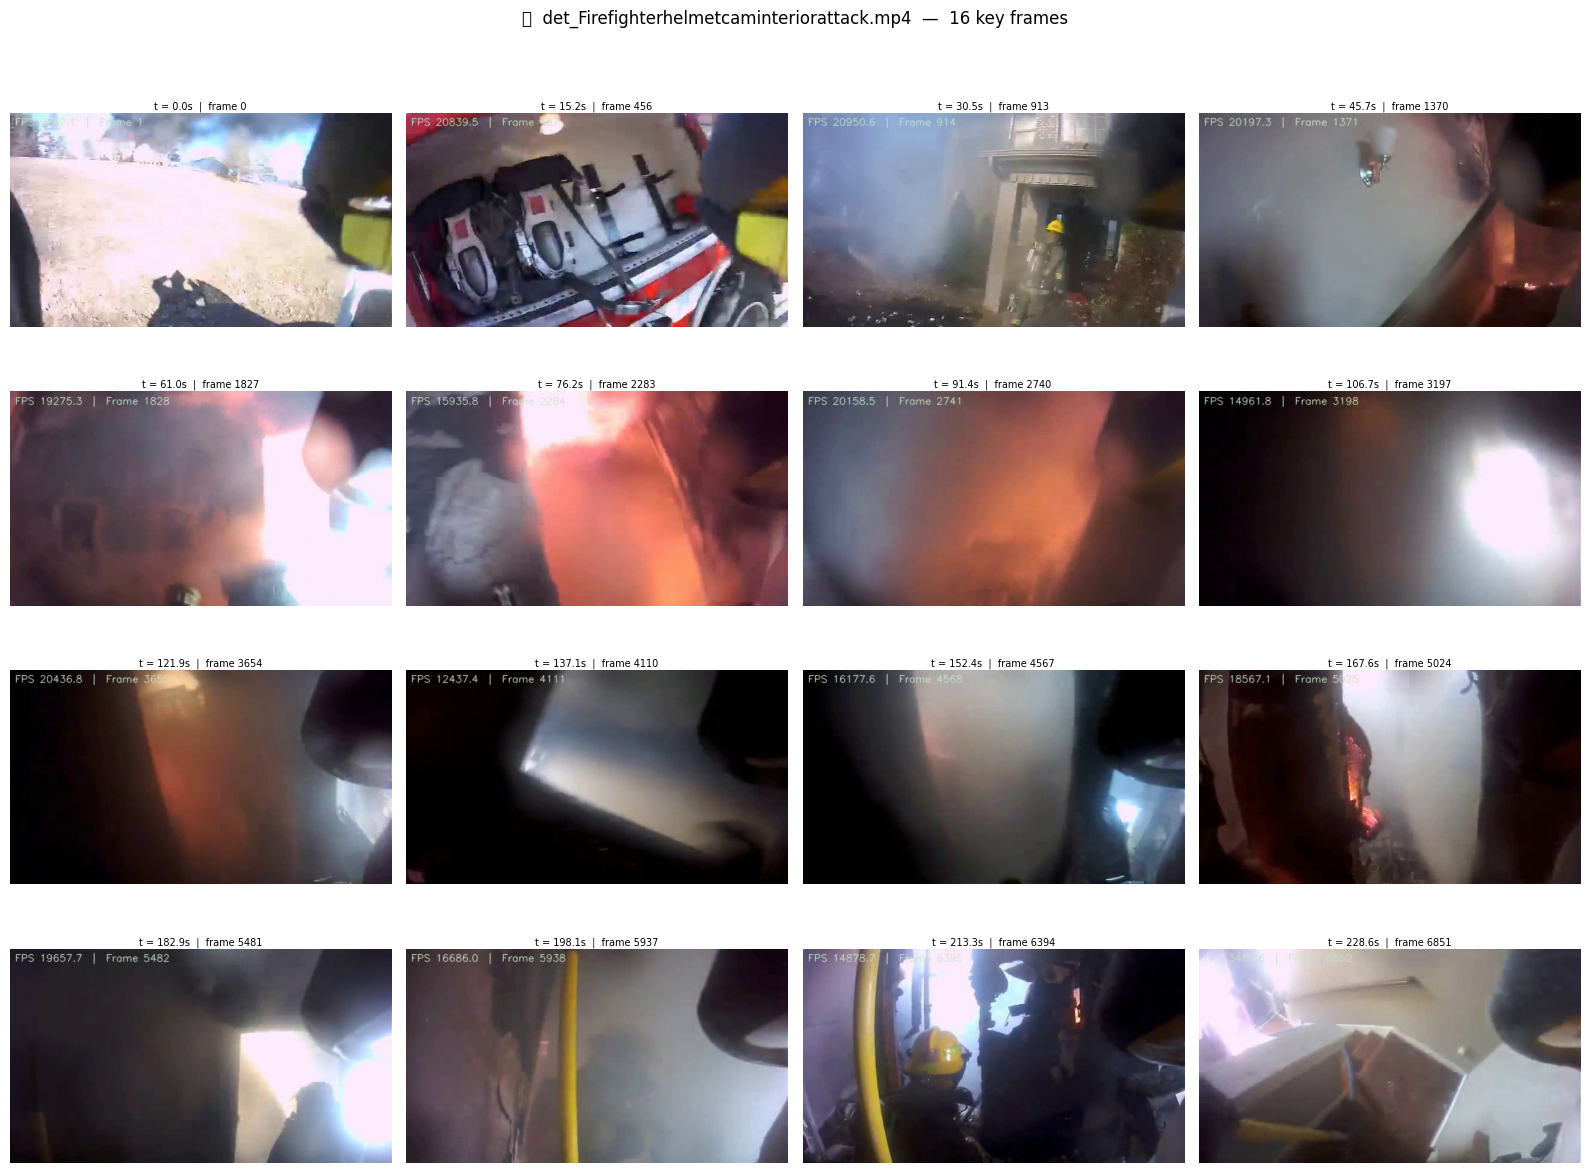

[DISPLAY] Showing 16 frames from: det_Firefighterhelmetcaminteriorattack.mp4
[DOWNLOAD] Full annotated video saved at: /content/fire_detection_model/outputs/visualizations/videos/det_Firefighterhelmetcaminteriorattack.mp4


In [ ]:
import cv2
import threading
import queue
import time
from pathlib import Path
from collections import deque
from dataclasses import dataclass, field
from typing import Optional
from tqdm.notebook import tqdm
import matplotlib.pyplot as plt
import numpy as np

# ── Video config — tune these without touching the pipeline ──────────────────
@dataclass
class VideoInferenceConfig:
    conf_threshold:  float = 0.50          # detection confidence threshold
    iou_threshold:   float = 0.45          # NMS IoU threshold
    vid_stride:      int   = 1             # process every Nth frame (1 = every frame)
    use_half:        bool  = True          # FP16 inference on GPU (~40% faster)
    write_queue_size:int   = 64            # writer buffer depth
    display_fps:     bool  = True          # overlay rolling FPS on output
    jpeg_quality:    int   = 92            # quality for any JPEG thumbnails

VIDEO_CFG = VideoInferenceConfig()


# ── Alert tracker — records fire enter/exit timestamps ──────────────────────
class FireAlertTracker:
    """
    Tracks fire detection across frames.
    Emits an alert entry when fire first appears and records when it clears.
    """
    def __init__(self, min_consecutive: int = 3):
        self.min_consecutive = min_consecutive
        self._consecutive    = 0
        self._in_alert       = False
        self._alert_start_ts = None
        self.alerts          = []
        self._peak_conf      = 0.0

    def update(self, has_fire: bool, confidence: float, timestamp_s: float):
        if has_fire:
            self._consecutive += 1
            self._peak_conf    = max(self._peak_conf, confidence)
            if self._consecutive >= self.min_consecutive and not self._in_alert:
                self._in_alert       = True
                self._alert_start_ts = timestamp_s
        else:
            if self._in_alert:
                self.alerts.append({
                    "start_s":   round(self._alert_start_ts, 2),
                    "end_s":     round(timestamp_s, 2),
                    "duration_s":round(timestamp_s - self._alert_start_ts, 2),
                    "peak_conf": round(self._peak_conf, 4),
                })
                self._in_alert  = False
                self._peak_conf = 0.0
            self._consecutive = 0

    def close(self, final_ts: float):
        """Call at end of video to close any open alert."""
        if self._in_alert:
            self.update(False, 0.0, final_ts)


# ── Frame annotator ───────────────────────────────────────────────────────────
def _draw_video_frame(frame: np.ndarray, detections,
                      fps: float, frame_idx: int,
                      alert_active: bool) -> np.ndarray:
    out = frame.copy()
    h, w = out.shape[:2]

    CLASS_COLORS_V = {
        "fire":    (0,   50,  220),
        "smoke":   (120, 120, 120),
        "default": (0,   200, 100),
    }

    for det in detections:
        cls   = det.class_name.lower()
        conf  = det.confidence
        color = CLASS_COLORS_V.get(cls, CLASS_COLORS_V["default"])

        x1 = max(0,  int(det.x_min))
        y1 = max(0,  int(det.y_min))
        x2 = min(w,  int(det.x_max))
        y2 = min(h,  int(det.y_max))

        # Semi-transparent fill
        overlay = out.copy()
        cv2.rectangle(overlay, (x1, y1), (x2, y2), color, -1)
        cv2.addWeighted(overlay, 0.22, out, 0.78, 0, out)

        # Solid border
        cv2.rectangle(out, (x1, y1), (x2, y2), color, 2)

        # Label — clamped so it never renders above frame top
        label = f"{det.class_name.upper()} {conf:.0%}"
        fs    = max(0.4, min(0.65, (x2 - x1) / 300))
        (lw, lh), bl = cv2.getTextSize(
            label, cv2.FONT_HERSHEY_SIMPLEX, fs, 1
        )
        ly = max(y1 - 5, lh + 4)
        cv2.rectangle(out,
                      (x1, ly - lh - 4), (x1 + lw + 4, ly + bl),
                      color, -1)
        cv2.putText(out, label, (x1 + 2, ly - 2),
                    cv2.FONT_HERSHEY_SIMPLEX, fs,
                    (255, 255, 255), 1, cv2.LINE_AA)

    # HUD — top-left: FPS + frame index
    if VIDEO_CFG.display_fps:
        hud = f"FPS {fps:4.1f}  |  Frame {frame_idx}"
        cv2.putText(out, hud, (8, 22),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.55,
                    (200, 230, 200), 1, cv2.LINE_AA)

    # ALERT banner — bottom of frame
    if alert_active:
        banner_h = 36
        overlay  = out.copy()
        cv2.rectangle(overlay, (0, h - banner_h), (w, h), (0, 0, 180), -1)
        cv2.addWeighted(overlay, 0.7, out, 0.3, 0, out)
        cv2.putText(out, "⚠  FIRE DETECTED  ⚠",
                    (w // 2 - 140, h - 10),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.75,
                    (255, 255, 255), 2, cv2.LINE_AA)

    return out


# ── Writer thread — decouples disk I/O from inference ────────────────────────
class AsyncVideoWriter:
    """
    Sits in its own thread, drains a queue of annotated frames,
    and writes them with cv2.VideoWriter.
    Inference never waits for disk.
    """
    _SENTINEL = None   # poison pill

    def __init__(self, output_path: Path, fps: float,
                 frame_size: tuple, queue_size: int = 64):
        self.output_path = output_path
        fourcc           = cv2.VideoWriter_fourcc(*"mp4v")
        self._writer     = cv2.VideoWriter(
            str(output_path), fourcc, fps, frame_size
        )
        self._q      = queue.Queue(maxsize=queue_size)
        self._thread = threading.Thread(target=self._worker, daemon=True)
        self._thread.start()

    def write(self, frame: np.ndarray):
        self._q.put(frame)    # blocks if queue full — back-pressure

    def close(self):
        self._q.put(self._SENTINEL)
        self._thread.join()
        self._writer.release()

    def _worker(self):
        while True:
            frame = self._q.get()
            if frame is self._SENTINEL:
                break
            self._writer.write(frame)


# ── Display annotated frames in output cell ───────────────────────────────────
def display_video_frames_in_colab(video_path: Path, num_frames: int = 16):
    """
    Extracts evenly-spaced frames from the annotated video and
    renders them as a matplotlib grid directly in the output cell.
    No base64, no re-encoding, no browser — instant display.
    Uses random-access cap.set(CAP_PROP_POS_FRAMES) so only the
    requested frames are decoded — no full sequential read.
    """
    cap          = cv2.VideoCapture(str(video_path))
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    src_fps      = cap.get(cv2.CAP_PROP_FPS) or 30.0

    if total_frames == 0:
        print("[WARNING] Could not read output video for display.")
        cap.release()
        return

    # Evenly-spaced indices across the full video
    indices = [int(i * total_frames / num_frames) for i in range(num_frames)]

    frames = []
    for idx in indices:
        cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
        ret, frame = cap.read()
        if ret:
            frames.append((idx, cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)))
    cap.release()

    if not frames:
        print("[WARNING] No frames extracted.")
        return

    cols      = 4
    rows      = (len(frames) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 4, rows * 3))
    axes      = np.array(axes).reshape(-1)

    for i, ax in enumerate(axes):
        if i < len(frames):
            frame_idx, rgb = frames[i]
            timestamp_s    = frame_idx / src_fps
            ax.imshow(rgb)
            ax.set_title(
                f"t = {timestamp_s:.1f}s  |  frame {frame_idx}",
                fontsize=7, pad=3
            )
        ax.axis("off")

    plt.suptitle(
        f"🎥  {video_path.name}  —  {len(frames)} key frames",
        fontsize=12, y=1.01
    )
    plt.tight_layout()
    plt.show()
    print(f"[DISPLAY] Showing {len(frames)} frames from: {video_path.name}")
    print(f"[DOWNLOAD] Full annotated video saved at: {video_path}")


# ── Main video inference function ─────────────────────────────────────────────
def run_video_inference(
        video_path: str,
        model_path: str,
        output_dir: Path,
        config: "ModelConfig",
        logger: "SimpleLogger",
        cfg: VideoInferenceConfig = VIDEO_CFG,
) -> tuple:
    """
    Full optimized video inference pipeline:
      - stream=True        → frames never fully buffered in RAM
      - half=True          → FP16 passed through predict() — safe, no dtype mismatch
      - vid_stride         → skip N frames
      - AsyncVideoWriter   → disk I/O off the hot path
      - FireAlertTracker   → timeline of fire events
    Returns (summary dict, output video Path).
    """
    from ultralytics import YOLO

    video_path = Path(video_path)
    if not video_path.exists():
        raise FileNotFoundError(f"Video not found: {video_path}")

    output_dir.mkdir(parents=True, exist_ok=True)
    out_path = output_dir / f"det_{video_path.stem}.mp4"

    # ── Load model ────────────────────────────────────────────────────────
    model    = YOLO(model_path)
    use_half = cfg.use_half and torch.cuda.is_available()
    # NOTE: do NOT call model.model.half() manually — it converts weight tensors
    # but leaves BatchNorm running_mean/running_var in FP32. When ultralytics
    # fuses Conv+BN at inference time this causes:
    #   RuntimeError: expected m1 and m2 to have the same dtype: c10::Half != float
    # Passing half=True inside model.predict() is the correct path — ultralytics
    # casts the full model including BN buffers consistently before fusion.
    if use_half:
        logger.info("Video inference: FP16 half-precision enabled via predict(half=True)")

    # ── Probe video metadata ──────────────────────────────────────────────
    cap          = cv2.VideoCapture(str(video_path))
    src_fps      = cap.get(cv2.CAP_PROP_FPS) or 30.0
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    frame_w      = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    frame_h      = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    cap.release()

    effective_fps = src_fps / cfg.vid_stride
    print(f"[VIDEO] {video_path.name}")
    print(f"  Source : {frame_w}×{frame_h}  {src_fps:.1f} FPS  {total_frames} frames")
    print(f"  Stride : every {cfg.vid_stride} frame(s)  →  {effective_fps:.1f} FPS output")
    print(f"  Half   : {use_half}  |  Conf: {cfg.conf_threshold}")
    print(f"  Output : {out_path}")
    logger.info(f"Video inference: {video_path.name} → {out_path}")

    # ── Wire up writer + tracker ──────────────────────────────────────────
    writer  = AsyncVideoWriter(out_path, effective_fps,
                               (frame_w, frame_h), cfg.write_queue_size)
    tracker = FireAlertTracker(min_consecutive=3)
    fps_buf = deque(maxlen=30)     # rolling FPS window

    # ── Inference loop ────────────────────────────────────────────────────
    frame_idx    = 0
    fire_frames  = 0
    smoke_frames = 0
    t_start      = time.time()

    predict_kwargs = dict(
        source     = str(video_path),
        conf       = cfg.conf_threshold,
        iou        = cfg.iou_threshold,
        vid_stride = cfg.vid_stride,
        stream     = True,       # generator — one frame at a time, no RAM buildup
        half       = use_half,   # ultralytics handles full-model FP16 cast safely
        verbose    = False,
    )

    pbar = tqdm(total=total_frames // cfg.vid_stride,
                desc="Video inference", unit="frame")

    for r in model.predict(**predict_kwargs):
        frame_idx  += 1
        t_frame     = time.time()
        timestamp_s = frame_idx / effective_fps

        # Parse detections from ultralytics Result object
        detections  = []
        class_names = model.names
        if r.boxes is not None:
            for box in r.boxes.data.cpu().numpy():
                x1, y1, x2, y2, conf, cls_id = box
                detections.append(type("Det", (), {
                    "class_name": class_names[int(cls_id)],
                    "confidence": float(conf),
                    "x_min": float(x1), "y_min": float(y1),
                    "x_max": float(x2), "y_max": float(y2),
                })())

        has_fire  = any(d.class_name.lower() == "fire"  for d in detections)
        has_smoke = any(d.class_name.lower() == "smoke" for d in detections)
        max_fire_conf = max(
            (d.confidence for d in detections
             if d.class_name.lower() == "fire"), default=0.0
        )

        if has_fire:  fire_frames  += 1
        if has_smoke: smoke_frames += 1

        tracker.update(has_fire, max_fire_conf, timestamp_s)

        # Rolling FPS
        fps_buf.append(time.time() - t_frame)
        rolling_fps = 1.0 / (sum(fps_buf) / len(fps_buf))

        # Draw + enqueue for async write
        annotated = _draw_video_frame(
            r.orig_img, detections, rolling_fps,
            frame_idx, tracker._in_alert
        )
        writer.write(annotated)
        pbar.update(1)

    pbar.close()
    tracker.close(frame_idx / effective_fps)
    writer.close()

    elapsed = time.time() - t_start
    summary = {
        "video":        video_path.name,
        "output":       str(out_path),
        "total_frames": frame_idx,
        "fire_frames":  fire_frames,
        "smoke_frames": smoke_frames,
        "fire_pct":     round(100 * fire_frames  / max(frame_idx, 1), 1),
        "smoke_pct":    round(100 * smoke_frames / max(frame_idx, 1), 1),
        "alert_events": tracker.alerts,
        "elapsed_s":    round(elapsed, 1),
        "avg_fps":      round(frame_idx / elapsed, 1),
    }

    print("\n" + "="*60)
    print("VIDEO INFERENCE SUMMARY")
    print("="*60)
    print(f"  Frames processed : {frame_idx}")
    print(f"  Fire frames      : {fire_frames}  ({summary['fire_pct']}%)")
    print(f"  Smoke frames     : {smoke_frames}  ({summary['smoke_pct']}%)")
    print(f"  Processing time  : {elapsed:.1f}s  ({summary['avg_fps']} FPS)")
    print(f"  Output video     : {out_path}")
    if tracker.alerts:
        print(f"\n  🔥 FIRE ALERT TIMELINE ({len(tracker.alerts)} event(s)):")
        for i, a in enumerate(tracker.alerts, 1):
            print(f"     [{i}] {a['start_s']}s → {a['end_s']}s  "
                  f"({a['duration_s']}s)  peak conf: {a['peak_conf']:.0%}")
    else:
        print("  No fire alert events detected.")
    print("="*60)
    logger.info(f"Video done: {summary['avg_fps']} FPS, "
                f"{len(tracker.alerts)} alert(s)")

    summary_path = output_dir / f"summary_{video_path.stem}.json"
    with open(summary_path, "w") as f:
        json.dump(summary, f, indent=2)
    print(f"  Summary JSON     : {summary_path}")

    return summary, out_path


# ── Entry point ───────────────────────────────────────────────────────────────
try:
    if "best_model_path" not in locals():
        raise ModelError(
            "No trained model found — run the training cell first",
            model_path="not set"
        )

    # ── Set your video path here ──────────────────────────────────────────
    VIDEO_SOURCE = "/content/Firefighterhelmetcaminteriorattack.mp4"   # ← change this
    # ─────────────────────────────────────────────────────────────────────

    video_output_dir = config.output_dir / "visualizations" / "videos"

    video_path = Path(VIDEO_SOURCE)
    if not video_path.exists():
        raise FileNotFoundError(
            f"Video not found: {VIDEO_SOURCE}\n"
            f"Upload your video to Colab first:\n"
            f"  Files panel (left sidebar) → Upload → then set VIDEO_SOURCE to the path."
        )

    summary, out_path = run_video_inference(
        video_path = str(video_path),
        model_path = best_model_path,
        output_dir = video_output_dir,
        config     = config,
        logger     = logger,
    )

    # ── Show key frames from annotated video instantly in output cell ─────
    display_video_frames_in_colab(out_path, num_frames=16)

except ModelError as e:
    e.log_and_raise(logger)
except FileNotFoundError as e:
    print(f"[ERROR] {e}")
    logger.error(str(e))
except Exception as e:
    print(f"[ERROR] Video inference failed: {e}")
    logger.error(f"Video inference failed: {e}")
    raise

2026-02-25 09:36:33 - INFO - Video inference: FP16 enabled via predict(half=True)
INFO:fire_detection:Video inference: FP16 enabled via predict(half=True)
2026-02-25 09:36:33 - INFO - Video inference: Firefighterhelmetcaminteriorattack.mp4 → /content/fire_detection_model/outputs/visualizations/videos/det_Firefighterhelmetcaminteriorattack.mp4
INFO:fire_detection:Video inference: Firefighterhelmetcaminteriorattack.mp4 → /content/fire_detection_model/outputs/visualizations/videos/det_Firefighterhelmetcaminteriorattack.mp4


[VIDEO] Firefighterhelmetcaminteriorattack.mp4
  Source : 640×360  30.0 FPS  7308 frames
  Stride : every 1 frame(s)  →  30.0 FPS output
  Half   : True  |  Conf: 0.5
  Output : /content/fire_detection_model/outputs/visualizations/videos/det_Firefighterhelmetcaminteriorattack.mp4


Video inference:   0%|          | 0/7308 [00:00<?, ?frame/s]

2026-02-25 09:38:26 - INFO - Video done: 64.9 FPS, 27 alert(s)
INFO:fire_detection:Video done: 64.9 FPS, 27 alert(s)



VIDEO INFERENCE SUMMARY
  Frames processed : 7308
  Fire frames      : 220  (3.0%)
  Smoke frames     : 0  (0.0%)
  Processing time  : 112.7s  (64.9 FPS)
  Output video     : /content/fire_detection_model/outputs/visualizations/videos/det_Firefighterhelmetcaminteriorattack.mp4

  🔥 FIRE ALERT TIMELINE (27 event(s)):
     [1] 17.02s → 17.08s  (0.07s)  peak conf: 65%
     [2] 25.53s → 25.66s  (0.13s)  peak conf: 81%
     [3] 33.8s → 33.83s  (0.03s)  peak conf: 59%
     [4] 37.44s → 37.47s  (0.03s)  peak conf: 68%
     [5] 46.45s → 46.48s  (0.03s)  peak conf: 54%
     [6] 99.9s → 99.97s  (0.07s)  peak conf: 79%
     [7] 100.07s → 100.17s  (0.1s)  peak conf: 78%
     [8] 101.23s → 101.27s  (0.03s)  peak conf: 56%
     [9] 117.75s → 117.78s  (0.03s)  peak conf: 67%
     [10] 117.92s → 117.95s  (0.03s)  peak conf: 57%
     [11] 136.94s → 137.04s  (0.1s)  peak conf: 77%
     [12] 142.64s → 142.68s  (0.03s)  peak conf: 52%
     [13] 142.78s → 142.84s  (0.07s)  peak conf: 55%
     [14] 142.94s

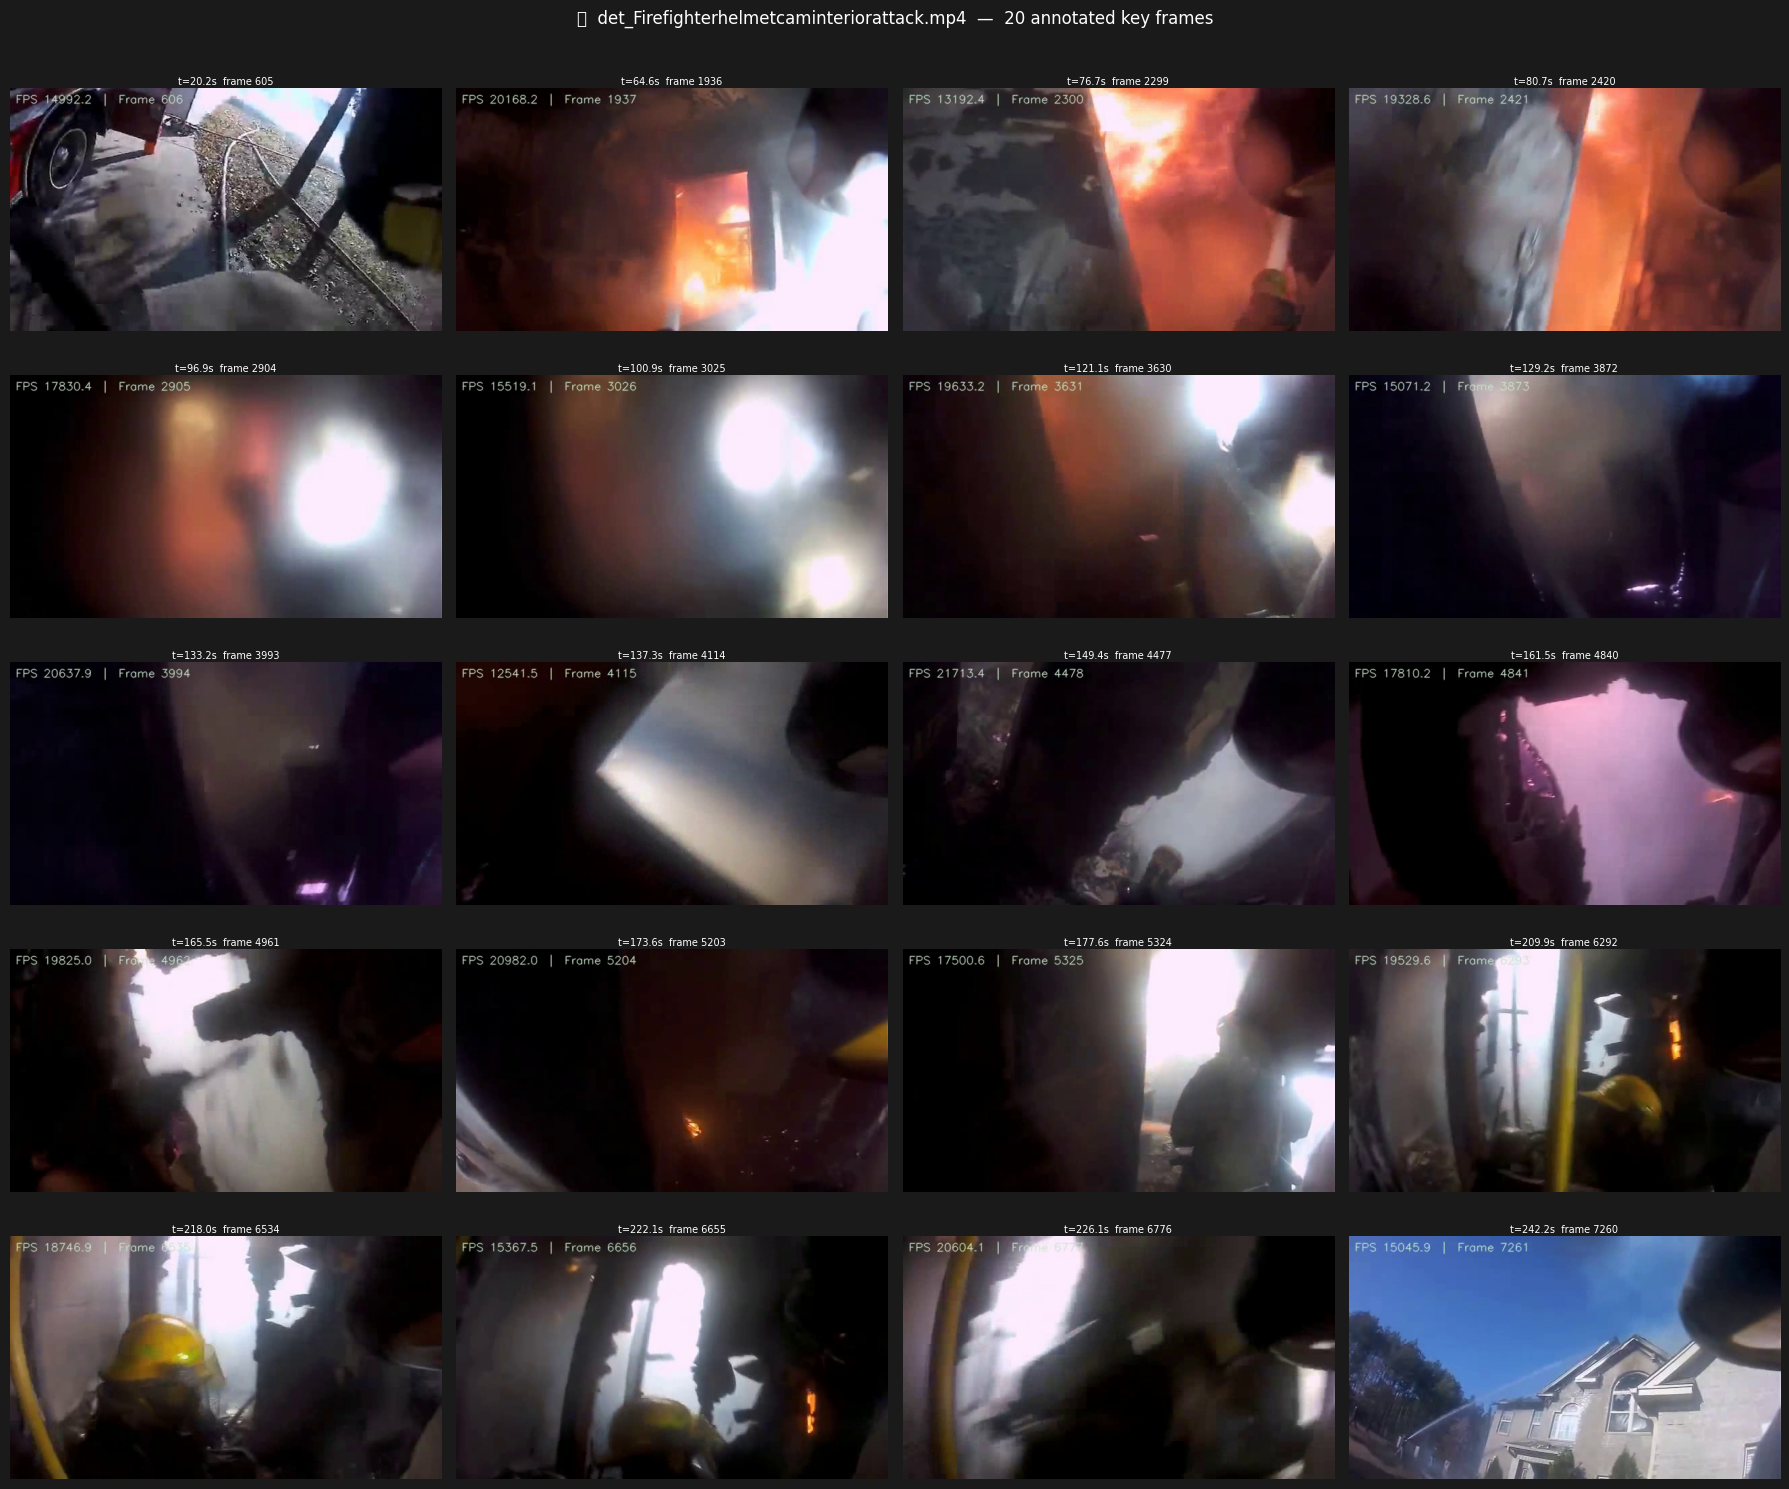


[DISPLAY] Showing 20 key frames from: det_Firefighterhelmetcaminteriorattack.mp4
[DOWNLOAD] Full annotated video saved at:
  /content/fire_detection_model/outputs/visualizations/videos/det_Firefighterhelmetcaminteriorattack.mp4


In [ ]:
import cv2
import threading
import queue
import time
from pathlib import Path
from collections import deque
from dataclasses import dataclass
from tqdm.notebook import tqdm
import matplotlib.pyplot as plt
import numpy as np
import json

# ── Video config ──────────────────────────────────────────────────────────────
@dataclass
class VideoInferenceConfig:
    conf_threshold:  float = 0.50
    iou_threshold:   float = 0.45
    vid_stride:      int   = 1             # process every Nth frame
    use_half:        bool  = True          # FP16 on GPU
    write_queue_size:int   = 64
    display_fps:     bool  = True
    display_frames:  int   = 20            # how many key frames to show in grid

VIDEO_CFG = VideoInferenceConfig()


# ── Threat level ──────────────────────────────────────────────────────────────
THREAT_LEVELS = {
    ("fire",  0.80): ("CRITICAL", (0,   0,   200)),
    ("fire",  0.60): ("HIGH",     (0,   80,  220)),
    ("fire",  0.00): ("MEDIUM",   (0,  160,  255)),
    ("smoke", 0.00): ("LOW",      (80, 160,  200)),
}

def get_threat_level(class_name: str, confidence: float):
    cls = class_name.lower()
    for (c, min_conf), (label, color) in sorted(
            THREAT_LEVELS.items(), key=lambda x: -x[0][1]):
        if cls == c and confidence >= min_conf:
            return label, color
    return "LOW", (80, 160, 200)


# ── Frame annotator ───────────────────────────────────────────────────────────
CLASS_COLORS = {
    "fire":    (0,   50,  220),
    "smoke":   (120, 120, 120),
    "default": (0,   200, 100),
}

def _draw_frame(frame: np.ndarray, detections,
                fps: float, frame_idx: int,
                alert_active: bool) -> np.ndarray:
    out = frame.copy()
    h, w = out.shape[:2]

    for det in detections:
        cls   = det.class_name.lower()
        conf  = det.confidence
        color = CLASS_COLORS.get(cls, CLASS_COLORS["default"])

        x1 = max(0,  int(det.x_min))
        y1 = max(0,  int(det.y_min))
        x2 = min(w,  int(det.x_max))
        y2 = min(h,  int(det.y_max))

        # Semi-transparent fill
        overlay = out.copy()
        cv2.rectangle(overlay, (x1, y1), (x2, y2), color, -1)
        cv2.addWeighted(overlay, 0.22, out, 0.78, 0, out)

        # Solid border
        cv2.rectangle(out, (x1, y1), (x2, y2), color, 2)

        # Class label + confidence — clamped above frame top
        label = f"{det.class_name.upper()}  {conf:.0%}"
        fs    = max(0.4, min(0.65, (x2 - x1) / 300))
        (lw, lh), bl = cv2.getTextSize(
            label, cv2.FONT_HERSHEY_SIMPLEX, fs, 1)
        ly = max(y1 - 5, lh + 4)
        cv2.rectangle(out,
                      (x1, ly - lh - 4), (x1 + lw + 4, ly + bl),
                      color, -1)
        cv2.putText(out, label, (x1 + 2, ly - 2),
                    cv2.FONT_HERSHEY_SIMPLEX, fs,
                    (255, 255, 255), 1, cv2.LINE_AA)

        # Threat badge — top-right corner of box
        threat_label, threat_color = get_threat_level(cls, conf)
        (tw, th), _ = cv2.getTextSize(
            threat_label, cv2.FONT_HERSHEY_SIMPLEX, 0.4, 1)
        badge_x = max(0, x2 - tw - 6)
        cv2.rectangle(out,
                      (badge_x, y1 + 2),
                      (badge_x + tw + 4, y1 + th + 8),
                      threat_color, -1)
        cv2.putText(out, threat_label,
                    (badge_x + 2, y1 + th + 4),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.4,
                    (255, 255, 255), 1, cv2.LINE_AA)

    # HUD — FPS + frame index
    if VIDEO_CFG.display_fps:
        hud = f"FPS {fps:4.1f}  |  Frame {frame_idx}"
        cv2.putText(out, hud, (8, 22),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.55,
                    (200, 230, 200), 1, cv2.LINE_AA)

    # Alert banner
    if alert_active:
        banner_h = 36
        overlay  = out.copy()
        cv2.rectangle(overlay, (0, h - banner_h), (w, h), (0, 0, 180), -1)
        cv2.addWeighted(overlay, 0.7, out, 0.3, 0, out)
        cv2.putText(out, "⚠  FIRE DETECTED  ⚠",
                    (w // 2 - 140, h - 10),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.75,
                    (255, 255, 255), 2, cv2.LINE_AA)

    return out


# ── Alert tracker ─────────────────────────────────────────────────────────────
class FireAlertTracker:
    def __init__(self, min_consecutive: int = 3):
        self.min_consecutive = min_consecutive
        self._consecutive    = 0
        self._in_alert       = False
        self._alert_start_ts = None
        self.alerts          = []
        self._peak_conf      = 0.0

    def update(self, has_fire: bool, confidence: float, timestamp_s: float):
        if has_fire:
            self._consecutive += 1
            self._peak_conf    = max(self._peak_conf, confidence)
            if self._consecutive >= self.min_consecutive and not self._in_alert:
                self._in_alert       = True
                self._alert_start_ts = timestamp_s
        else:
            if self._in_alert:
                self.alerts.append({
                    "start_s":   round(self._alert_start_ts, 2),
                    "end_s":     round(timestamp_s, 2),
                    "duration_s":round(timestamp_s - self._alert_start_ts, 2),
                    "peak_conf": round(self._peak_conf, 4),
                })
                self._in_alert  = False
                self._peak_conf = 0.0
            self._consecutive = 0

    def close(self, final_ts: float):
        if self._in_alert:
            self.update(False, 0.0, final_ts)


# ── Async writer ──────────────────────────────────────────────────────────────
class AsyncVideoWriter:
    _SENTINEL = None

    def __init__(self, output_path: Path, fps: float,
                 frame_size: tuple, queue_size: int = 64):
        self.output_path = output_path
        fourcc           = cv2.VideoWriter_fourcc(*"mp4v")
        self._writer     = cv2.VideoWriter(
            str(output_path), fourcc, fps, frame_size)
        self._q      = queue.Queue(maxsize=queue_size)
        self._thread = threading.Thread(target=self._worker, daemon=True)
        self._thread.start()

    def write(self, frame: np.ndarray):
        self._q.put(frame)

    def close(self):
        self._q.put(self._SENTINEL)
        self._thread.join()
        self._writer.release()

    def _worker(self):
        while True:
            frame = self._q.get()
            if frame is self._SENTINEL:
                break
            self._writer.write(frame)


# ── Display grid of key frames from annotated video ───────────────────────────
def display_detection_grid(video_path: Path,
                            num_frames: int = 20,
                            prefer_detections: bool = True):
    """
    Reads evenly-spaced frames from the saved annotated video and
    renders them as a matplotlib grid in the output cell.

    prefer_detections=True  → tries to pick frames that have bounding boxes
    drawn (non-uniform background), giving a more informative grid.
    No re-encoding, no base64, no browser. Instant.
    """
    cap          = cv2.VideoCapture(str(video_path))
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    src_fps      = cap.get(cv2.CAP_PROP_FPS) or 30.0

    if total_frames == 0:
        print("[WARNING] Could not read output video for display.")
        cap.release()
        return

    # ── Pass 1: evenly-spaced candidate indices ───────────────────────────
    step       = max(1, total_frames // (num_frames * 3))  # sample 3× more
    candidates = list(range(0, total_frames, step))

    frames_raw = []
    for idx in candidates:
        cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
        ret, frame = cap.read()
        if ret:
            frames_raw.append((idx, frame))
    cap.release()

    # ── Pass 2: prefer frames with detections ────────────────────────────
    # Proxy: frames with detections have colored rectangles →
    # higher color variance than plain background frames.
    if prefer_detections and len(frames_raw) > num_frames:
        def color_variance(f):
            return float(np.var(cv2.cvtColor(f, cv2.COLOR_BGR2HSV)[:, :, 1]))

        frames_raw.sort(key=lambda x: color_variance(x[1]), reverse=True)

    # Take the top num_frames, then sort back by index for chronological order
    selected = sorted(frames_raw[:num_frames], key=lambda x: x[0])

    # ── Render grid ───────────────────────────────────────────────────────
    cols      = 4
    rows      = (len(selected) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols,
                             figsize=(cols * 4.5, rows * 3),
                             facecolor="#1a1a1a")
    axes = np.array(axes).reshape(-1)

    for i, ax in enumerate(axes):
        ax.set_facecolor("#1a1a1a")
        if i < len(selected):
            fidx, bgr = selected[i]
            rgb        = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
            ts         = fidx / src_fps
            ax.imshow(rgb)
            ax.set_title(
                f"t={ts:.1f}s  frame {fidx}",
                fontsize=7, pad=3,
                color="white"
            )
        ax.axis("off")

    plt.suptitle(
        f"🎥  {video_path.name}  —  {len(selected)} annotated key frames",
        fontsize=12, y=1.005, color="white"
    )
    plt.tight_layout()
    plt.show()

    print(f"\n[DISPLAY] Showing {len(selected)} key frames from: {video_path.name}")
    print(f"[DOWNLOAD] Full annotated video saved at:\n  {video_path}")


# ── Main inference function ───────────────────────────────────────────────────
def run_video_inference(
        video_path: str,
        model_path: str,
        output_dir: Path,
        config,
        logger,
        cfg: VideoInferenceConfig = VIDEO_CFG,
) -> tuple:
    from ultralytics import YOLO

    video_path = Path(video_path)
    if not video_path.exists():
        raise FileNotFoundError(f"Video not found: {video_path}")

    output_dir.mkdir(parents=True, exist_ok=True)
    out_path = output_dir / f"det_{video_path.stem}.mp4"

    # ── Load model ────────────────────────────────────────────────────────
    model    = YOLO(model_path)
    use_half = cfg.use_half and torch.cuda.is_available()
    # NOTE: do NOT call model.model.half() manually — it converts weight
    # tensors but leaves BatchNorm running_mean/running_var in FP32.
    # When ultralytics fuses Conv+BN at inference time this causes:
    #   RuntimeError: expected m1 and m2 to have same dtype: c10::Half != float
    # Passing half=True inside model.predict() is the correct path.
    if use_half:
        logger.info("Video inference: FP16 enabled via predict(half=True)")

    # ── Probe video metadata ──────────────────────────────────────────────
    cap          = cv2.VideoCapture(str(video_path))
    src_fps      = cap.get(cv2.CAP_PROP_FPS) or 30.0
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    frame_w      = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    frame_h      = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    cap.release()

    effective_fps = src_fps / cfg.vid_stride
    print(f"[VIDEO] {video_path.name}")
    print(f"  Source : {frame_w}×{frame_h}  {src_fps:.1f} FPS  {total_frames} frames")
    print(f"  Stride : every {cfg.vid_stride} frame(s)  →  {effective_fps:.1f} FPS output")
    print(f"  Half   : {use_half}  |  Conf: {cfg.conf_threshold}")
    print(f"  Output : {out_path}")
    logger.info(f"Video inference: {video_path.name} → {out_path}")

    # ── Wire up writer + tracker ──────────────────────────────────────────
    writer  = AsyncVideoWriter(out_path, effective_fps,
                               (frame_w, frame_h), cfg.write_queue_size)
    tracker = FireAlertTracker(min_consecutive=3)
    fps_buf = deque(maxlen=30)

    # ── Inference loop ────────────────────────────────────────────────────
    frame_idx    = 0
    fire_frames  = 0
    smoke_frames = 0
    t_start      = time.time()

    predict_kwargs = dict(
        source     = str(video_path),
        conf       = cfg.conf_threshold,
        iou        = cfg.iou_threshold,
        vid_stride = cfg.vid_stride,
        stream     = True,       # generator — one frame at a time
        half       = use_half,   # ultralytics handles full FP16 cast safely
        verbose    = False,
    )

    pbar = tqdm(total=total_frames // cfg.vid_stride,
                desc="Video inference", unit="frame")

    for r in model.predict(**predict_kwargs):
        frame_idx  += 1
        t_frame     = time.time()
        timestamp_s = frame_idx / effective_fps

        detections  = []
        class_names = model.names
        if r.boxes is not None:
            for box in r.boxes.data.cpu().numpy():
                x1, y1, x2, y2, conf, cls_id = box
                detections.append(type("Det", (), {
                    "class_name": class_names[int(cls_id)],
                    "confidence": float(conf),
                    "x_min": float(x1), "y_min": float(y1),
                    "x_max": float(x2), "y_max": float(y2),
                })())

        has_fire  = any(d.class_name.lower() == "fire"  for d in detections)
        has_smoke = any(d.class_name.lower() == "smoke" for d in detections)
        max_fire_conf = max(
            (d.confidence for d in detections
             if d.class_name.lower() == "fire"), default=0.0
        )

        if has_fire:  fire_frames  += 1
        if has_smoke: smoke_frames += 1

        tracker.update(has_fire, max_fire_conf, timestamp_s)

        fps_buf.append(time.time() - t_frame)
        rolling_fps = 1.0 / (sum(fps_buf) / len(fps_buf))

        annotated = _draw_frame(
            r.orig_img, detections, rolling_fps,
            frame_idx, tracker._in_alert
        )
        writer.write(annotated)
        pbar.update(1)

    pbar.close()
    tracker.close(frame_idx / effective_fps)
    writer.close()

    elapsed = time.time() - t_start
    summary = {
        "video":        video_path.name,
        "output":       str(out_path),
        "total_frames": frame_idx,
        "fire_frames":  fire_frames,
        "smoke_frames": smoke_frames,
        "fire_pct":     round(100 * fire_frames  / max(frame_idx, 1), 1),
        "smoke_pct":    round(100 * smoke_frames / max(frame_idx, 1), 1),
        "alert_events": tracker.alerts,
        "elapsed_s":    round(elapsed, 1),
        "avg_fps":      round(frame_idx / elapsed, 1),
    }

    print("\n" + "="*60)
    print("VIDEO INFERENCE SUMMARY")
    print("="*60)
    print(f"  Frames processed : {frame_idx}")
    print(f"  Fire frames      : {fire_frames}  ({summary['fire_pct']}%)")
    print(f"  Smoke frames     : {smoke_frames}  ({summary['smoke_pct']}%)")
    print(f"  Processing time  : {elapsed:.1f}s  ({summary['avg_fps']} FPS)")
    print(f"  Output video     : {out_path}")
    if tracker.alerts:
        print(f"\n  🔥 FIRE ALERT TIMELINE ({len(tracker.alerts)} event(s)):")
        for i, a in enumerate(tracker.alerts, 1):
            print(f"     [{i}] {a['start_s']}s → {a['end_s']}s  "
                  f"({a['duration_s']}s)  peak conf: {a['peak_conf']:.0%}")
    else:
        print("  No fire alert events detected.")
    print("="*60)
    logger.info(f"Video done: {summary['avg_fps']} FPS, "
                f"{len(tracker.alerts)} alert(s)")

    summary_path = output_dir / f"summary_{video_path.stem}.json"
    with open(summary_path, "w") as f:
        json.dump(summary, f, indent=2)
    print(f"  Summary JSON     : {summary_path}")

    return summary, out_path


# ── Entry point ───────────────────────────────────────────────────────────────
try:
    if "best_model_path" not in locals():
        raise ModelError(
            "No trained model found — run the training cell first",
            model_path="not set"
        )

    # ── Set your video path here ──────────────────────────────────────────
    VIDEO_SOURCE = "/content/Firefighterhelmetcaminteriorattack.mp4"   # ← change this
    # ─────────────────────────────────────────────────────────────────────

    video_output_dir = config.output_dir / "visualizations" / "videos"

    video_path = Path(VIDEO_SOURCE)
    if not video_path.exists():
        raise FileNotFoundError(
            f"Video not found: {VIDEO_SOURCE}\n"
            f"Upload your video to Colab first:\n"
            f"  Files panel (left sidebar) → Upload → then set VIDEO_SOURCE to the path."
        )

    summary, out_path = run_video_inference(
        video_path = str(video_path),
        model_path = best_model_path,
        output_dir = video_output_dir,
        config     = config,
        logger     = logger,
    )

    # ── Display annotated key frames instantly in output cell ─────────────
    display_detection_grid(out_path, num_frames=VIDEO_CFG.display_frames)

except ModelError as e:
    e.log_and_raise(logger)
except FileNotFoundError as e:
    print(f"[ERROR] {e}")
    logger.error(str(e))
except Exception as e:
    print(f"[ERROR] Video inference failed: {e}")
    logger.error(f"Video inference failed: {e}")
    raise